In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")

# 1. Análisis Exploratorio y Limpieza

## 1.1 Análisis inicial

In [3]:
# abrimos el archivo y vemos el tamaño de nuestro dataset. 
df = pd.read_csv("data/25-testcar-2026-01-21.xlsx - Sheet1.csv")
print(f"las dimensiones del dataset son: {df.shape[0]} filas (registros) x {df.shape[1]} columnas (variables)") 


las dimensiones del dataset son: 4287 filas (registros) x 67 columnas (variables)


In [4]:
df.head()

,Model Year,Vehicle Manufacturer Name,Veh Mfr Code,Represented Test Veh Make,Represented Test Veh Model,Test Vehicle ID,Test Veh Configuration #,Test Veh Displacement (L),Actual Tested Testgroup,Vehicle Type,Rated Horsepower,# of Cylinders and Rotors,Engine Code,Tested Transmission Type Code,Tested Transmission Type,# of Gears,Transmission Lockup?,Drive System Code,Drive System Description,Transmission Overdrive Code,Transmission Overdrive Desc,Equivalent Test Weight (lbs.),Axle Ratio,N/V Ratio,Shift Indicator Light Use Cd,Shift Indicator Light Use Desc,Test Number,Test Originator,Analytically Derived FE?,ADFE Test Number,ADFE Total Road Load HP,ADFE Equiv. Test Weight (lbs.),ADFE N/V Ratio,Test Procedure Cd,Test Procedure Description,Test Fuel Type Cd,Test Fuel Type Description,Test Category,THC (g/mi),CO (g/mi),CO2 (g/mi),NOx (g/mi),PM (g/mi),CH4 (g/mi),N2O (g/mi),RND_ADJ_FE,FE_UNIT,FE Bag 1,FE Bag 2,FE Bag 3,FE Bag 4,DT-Inertia Work Ratio Rating,DT-Absolute Speed Change Ratg,DT-Energy Economy Rating,Target Coef A (lbf),Target Coef B (lbf/mph),Target Coef C (lbf/mph**2),Set Coef A (lbf),Set Coef B (lbf/mph),Set Coef C (lbf/mph**2),Aftertreatment Device Cd,Aftertreatment Device Desc,Police - Emergency Vehicle?,Averaging Group ID,Averaging Weighting Factor,Averaging Method Cd,Averging Method Desc
0,2025,aston martin,ASX,Aston Martin,DB12 V8,5723PT5601,0,"4,000",RASXV04.0AES,Car,680,8.0,177850,A,Automatic,8,Y,R,"2-Wheel Drive, Rear",2,Top gear ratio < 1,4500,"3,08","24,8",1,Not eqipped,RASX10082337,MFR,No,NaN,NaN,NaN,NaN,21,Federal fuel 2-day exhaust (w/can load),61,Tier 2 Cert Gasoline,FTP,"0,0256000","0,5360000","484,3290000","0,0080000",NaN,"0,0089000","0,0039000","18,3",MPG,"17,8185000","17,0058000","21,6199000",NaN,"-0,1000000","-0,2000000","-0,3500000","53,240","0,22280","0,022100","5,670","0,00830","0,02210",TWC,Three-way catalyst,N,NaN,NaN,N,No averaging
1,2025,aston martin,ASX,Aston Martin,DB12 V8,5723PT5601,0,"4,000",RASXV04.0AES,Car,680,8.0,177850,A,Automatic,8,Y,R,"2-Wheel Drive, Rear",2,Top gear ratio < 1,4500,"3,08","24,8",1,Not eqipped,RASX10082338,MFR,No,NaN,NaN,NaN,NaN,3,HWFE,61,Tier 2 Cert Gasoline,HWY,"0,0007000","0,0400000","283,2350000","0,0070000",NaN,NaN,NaN,"31,3",MPG,NaN,NaN,NaN,NaN,"8,7200000","7,0900000","-0,4200000","53,240","0,22280","0,022100","5,670","0,00830","0,02210",TWC,Three-way catalyst,N,NaN,NaN,N,No averaging
2,2025,aston martin,ASX,Aston Martin,DBX 707,8841PT8473,0,"4,000",PASXJ04.0AEX,Both,707,8.0,177950,A,Automatic,9,Y,4,4-Wheel Drive,2,Top gear ratio < 1,5500,"3,27","22,0",1,Not eqipped,PASX10073957,MFR,No,NaN,NaN,NaN,NaN,21,Federal fuel 2-day exhaust (w/can load),61,Tier 2 Cert Gasoline,FTP,"0,0156000","0,1500000","486,7500000","0,0110000","0,0004000","0,0040000",NaN,"18,5",MPG,"17,7311000","17,8284000","20,4728000",NaN,"-0,8400000","-1,0000000","-0,3800000","60,680","-0,32860","0,037300","-4,880","-0,53180","0,03670",TWC,Three-way catalyst,N,NaN,NaN,N,No averaging
3,2025,aston martin,ASX,Aston Martin,DBX 707,8841PT8473,0,"4,000",PASXJ04.0AEX,Both,707,8.0,177950,A,Automatic,9,Y,4,4-Wheel Drive,2,Top gear ratio < 1,5500,"3,27","22,0",1,Not eqipped,PASX10073958,MFR,No,NaN,NaN,NaN,NaN,3,HWFE,61,Tier 2 Cert Gasoline,HWY,0,"0,0200000","331,4800000","0,0030000",NaN,NaN,NaN,"27,2",MPG,NaN,NaN,NaN,NaN,"-5,0300000","-4,1600000","-1,2100000","60,680","-0,32860","0,037300","-4,880","-0,53180","0,03670",TWC,Three-way catalyst,N,NaN,NaN,N,No averaging
4,2025,aston martin,ASX,Aston Martin,Vanquish,370TT7334,0,"5,200",SASXV05.2AMV,Car,825,12.0,AM34A/,A,Automatic,8,N,R,"2-Wheel Drive, Rear",2,Top gear ratio < 1,4500,"2,93","22,6",1,Not eqipped,SASX10087770,MFR,No,NaN,NaN,NaN,NaN,21,Federal fuel 2-day exhaust (w/can load),61,Tier 2 Cert Gasoline,FTP,"0,0170000","0,8260000","546,3510000","0,0250000",NaN,"0,0080000","0,0050000","16,4",MPG,"15,6150000","15,5160000","19,1550000",NaN,"1,6170000","0,9120000","0,0330000","49,170","0,35270","0,022600","-0,570","-0,00290","0,01280",TWC,Three-way catalyst,N,NaN

In [19]:
df.describe()

,Model Year,Test Veh Configuration #,Rated Horsepower,# of Cylinders and Rotors,# of Gears,Transmission Overdrive Code,Equivalent Test Weight (lbs.),Shift Indicator Light Use Cd,ADFE Equiv. Test Weight (lbs.),Test Procedure Cd,Test Fuel Type Cd
count,4287.0,4287.000000,4287.000000,3617.000000,4287.000000,4287.000000,4287.000000,4287.000000,212.000000,4287.000000,4287.000000
mean,2025.0,0.908328,340.698157,5.222007,6.052018,1.844180,4818.783532,1.073478,4883.254717,36.230231,57.800093
std,0.0,1.255968,175.121581,1.624339,3.397571,0.362727,985.818195,0.475693,706.324859,35.642649,10.737065
min,2025.0,0.000000,1.000000,3.000000,1.000000,1.000000,2750.000000,1.000000,3125.000000,2.000000,19.000000
25%,2025.0,0.000000,201.000000,4.000000,1.000000,2.000000,4000.000000,1.000000,4250.000000,3.000000,61.000000
50%,2025.0,0.000000,305.000000,4.000000,8.000000,2.000000,4750.000000,1.000000,5000.000000,21.000000,61.000000
75%,2025.0,1.000000,409.000000,6.000000,8.000000,2.000000,5500.000000,1.000000,5500.000000,81.000000,61.000000
max,2025.0,8.000000,1948.000000,16.000000,10.000000,2.000000,9000.000000,5.000000,6000.000000,95.000000,62.000000


#### 1.1.1 Análisis tipos de variables

In [5]:
# para revisar los tipos de datos
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4287 entries, 0 to 4286
Data columns (total 67 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Model Year                      4287 non-null   int64  
 1   Vehicle Manufacturer Name       4287 non-null   object 
 2   Veh Mfr Code                    4287 non-null   object 
 3   Represented Test Veh Make       4287 non-null   object 
 4   Represented Test Veh Model      4287 non-null   object 
 5   Test Vehicle ID                 4287 non-null   object 
 6   Test Veh Configuration #        4287 non-null   int64  
 7   Test Veh Displacement (L)       4287 non-null   object 
 8   Actual Tested Testgroup         4287 non-null   object 
 9   Vehicle Type                    4287 non-null   object 
 10  Rated Horsepower                4287 non-null   int64  
 11  # of Cylinders and Rotors       3617 non-null   float64
 12  Engine Code                     42

In [6]:
# isna nos indica si un valor es un NaN o no. COn el sum tomamos todos estos números
# Determinamos cuantos nans hay
df.isna().sum()

Model Year                        0
Vehicle Manufacturer Name         0
Veh Mfr Code                      0
Represented Test Veh Make         0
Represented Test Veh Model        0
                               ... 
Police - Emergency Vehicle?       0
Averaging Group ID             4212
Averaging Weighting Factor     4212
Averaging Method Cd               0
Averging Method Desc              0
Length: 67, dtype: int64

#### 1.1.2 Análisis de la granularidad de los datos

In [7]:
clave = ["Veh Mfr Code", "Test Vehicle ID", "Test Veh Configuration #"]
print(f"Filas: {len(df)}")
print(f"Configuraciones únicas (clave EPA):", df.groupby(clave).ngroups)
print(f"Filas completamente duplicadas:", df.duplicated().sum())
print(f"Test Number repetidos:", df["Test Number"].duplicated().sum())
print()
print(f"Ensayos por configuración:")
# calcula la frecuencia de ensayo por vehículo. Cuantos vehículos tiene 1 ensayo, 2 ensayos, y así
print(df.groupby(clave).size().value_counts().sort_index())
print()

Filas: 4287
Configuraciones únicas (clave EPA): 1448
Filas completamente duplicadas: 0
Test Number repetidos: 273

Ensayos por configuración:
1     155
2     766
3     118
4     132
5     149
6      54
7      22
8      12
9      20
10     14
12      4
15      1
16      1
Name: count, dtype: int64



In [8]:
# copiamos el conjunto para preservarlo
clean_df= df.copy()

#### 1.1.11 Conversion de str a float

In [13]:
columnas_float = [
    'Set Coef A (lbf)',
    'Set Coef B (lbf/mph)',
    'Set Coef C (lbf/mph**2)',
    "Target Coef A (lbf)"
]

# Reemplazar comas por puntos y convertir a float
clean_df[columnas_float] = (
    clean_df[columnas_float]
    .replace(',', '.', regex=True)
    .astype(float)
)

#### 1.1.3 Análisis valores duplicados

In [14]:
test_number_repetidos = clean_df[
clean_df['Test Number'].duplicated(keep=False)
].sort_values('Test Number')

columnas_diferentes = test_number_repetidos.columns[
test_number_repetidos.nunique(dropna=False) > 1
]

for numero, grupo in test_number_repetidos.groupby('Test Number'):
    columnas_diferentes = grupo.columns[
        grupo.nunique(dropna=False) > 1
    ]

    if len(columnas_diferentes) > 0:
        print(f"\nTest Number: {numero}")
        display(grupo[columnas_diferentes])


Test Number: NFEX10067550


,Aftertreatment Device Cd,Aftertreatment Device Desc
782,TWC,Three-way catalyst
783,OT,Other



Test Number: NFEX10067551


,Aftertreatment Device Cd,Aftertreatment Device Desc
784,TWC,Three-way catalyst
785,OT,Other



Test Number: NFEX10067679


,Aftertreatment Device Cd,Aftertreatment Device Desc
786,OT,Other
787,TWC,Three-way catalyst


... (416 outputs left out)


Test Number: SGMX91006218


,Aftertreatment Device Cd,Aftertreatment Device Desc
1502,OC,Oxidation catalyst
1500,DPF,Diesel Particulate Filter
1501,SCR,Selective Catalytic Reduction



Test Number: SGMX91006219


,Aftertreatment Device Cd,Aftertreatment Device Desc
1505,OC,Oxidation catalyst
1504,SCR,Selective Catalytic Reduction
1503,DPF,Diesel Particulate Filter


Solucion:

In [15]:
import pandas as pd
import numpy as np

# 1. TRATAMIENTO DE SISTEMAS DE POSTRATAMIENTO (Concatenación de textos)
# Función para concatenar valores únicos separados por coma
def concatenar_valores_unicos(series):
    # Elimina los nulos, convierte a texto, extrae valores únicos y los une con ", "
    valores = series.dropna().astype(str).unique()
    return ", ".join(valores) if len(valores) > 0 else np.nan

# Agrupamos por 'Test Number' y concatenamos los textos de los dispositivos
aftertreatment_agg = clean_df.groupby('Test Number').agg({
    'Aftertreatment Device Cd': concatenar_valores_unicos,
    'Aftertreatment Device Desc': concatenar_valores_unicos
}).reset_index()

# 2. TRATAMIENTO DE COEFICIENTES DE DINAMÓMETRO (Promedio matemático)
# Agrupamos por 'Test Number' y promediamos los coeficientes
coef_agg = clean_df.groupby('Test Number').agg({
    'Set Coef A (lbf)': 'mean',
    'Set Coef B (lbf/mph)': 'mean',
    'Set Coef C (lbf/mph**2)': 'mean'
}).reset_index()


# 3. CONSOLIDACIÓN DEL DATASET FINAL
# Primero, eliminamos las columnas problemáticas del dataframe original 
# y nos quedamos solo con la primera ocurrencia de cada Test Number (borramos los duplicados).
columnas_a_borrar = [
    'Aftertreatment Device Cd', 'Aftertreatment Device Desc',
    'Set Coef A (lbf)', 'Set Coef B (lbf/mph)', 'Set Coef C (lbf/mph**2)'
]
df_sin_duplicados = clean_df.drop(columns=columnas_a_borrar).drop_duplicates(subset=['Test Number'], keep='first')

# Luego, cruzamos (Merge) el dataframe limpio con las tablas agrupadas que creamos en los pasos 1 y 2
df_consolidado = pd.merge(df_sin_duplicados, aftertreatment_agg, on='Test Number', how='left')
df_consolidado = pd.merge(df_consolidado, coef_agg, on='Test Number', how='left')

# Verificamos que el problema esté resuelto
print(f"Test Number repetidos tras la limpieza: {df_consolidado['Test Number'].duplicated().sum()}")

# Actualizar clean_df con el dataset consolidado
clean_df = df_consolidado.copy()

Test Number repetidos tras la limpieza: 0


#### 1.1.4 Análisis ensayos por categoría

In [16]:
# muestra los ensayos según categoria o protocolo aplicado
print(df["Test Category"].value_counts())

Test Category
FTP     1577
HWY     1340
CD       695
US06     412
SC03     263
Name: count, dtype: int64


#### 1.1.5 Conversión de tipos de datos en variables categóricas

Se convierten las columnas `Test Veh Configuration #`, `Transmission Overdrive Code`, `Shift Indicator Light Use Cd`, `Test Procedure Cd` y `Test Fuel Type Cd` de tipo entero (`int64`) a tipo texto (`object`).

**Justificación:** Aunque están registradas numéricamente en el archivo original, estas variables representan códigos categóricos nominales sin orden ni magnitud matemática. Mantenerlas como enteros constituye una infracción de tipo de dato y distorsionaría los análisis estadísticos cuantitativos.

In [17]:
columnas_categoricas = [
    'Test Veh Configuration #',
    'Transmission Overdrive Code',
    'Shift Indicator Light Use Cd',
    'Test Procedure Cd',
    'Test Fuel Type Cd',
]

clean_df[columnas_categoricas] = clean_df[columnas_categoricas].astype(str)

#### 1.1.6 Conversión de variables categóricas binarias (Y/N) a booleanas (True/False).

Al presentar únicamente dos valores ('Y' y 'N'), estas columnas constituyen variables binarias. Mapearlas a valores booleanos (True / False) permite expresar correctamente su naturaleza estadística y evita confusiones durante la manipulación y el análisis de los datos.

In [18]:
cols_binarias = [
    'Transmission Lockup?',
    'Analytically Derived FE?',
    'Police - Emergency Vehicle?',
]

for col in cols_binarias:
    clean_df[col] = clean_df[col] == 'Y'

<!-- ### Solución de filas "repetidas" -->

#### 1.1.7 Análisis de variables categóricas de las hipótesis

In [19]:
import matplotlib.pyplot as plt

def graficar_frecuencias(columna):
    frecuencias = clean_df[columna].value_counts(
        normalize=True
    ) * 100

    frecuencias.plot(kind='bar', figsize=(10, 5))

    plt.title(f'Distribución de {columna}')
    plt.xlabel('Categorías')
    plt.ylabel('Porcentaje (%)')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

##### 1.1.7.1 Test Fuel Type Description

Combustible/fuente de energía utilizada.

In [20]:
clean_df['Test Fuel Type Description'].value_counts()

Test Fuel Type Description
Tier 2 Cert Gasoline                             3064
Electricity                                       654
Cold CO Regular (Tier 2)                          159
Cold CO Premium (Tier 2)                           57
Federal Cert Diesel 7-15 PPM Sulfur                50
E85 (85% Ethanol 15% EPA Unleaded Gasoline)        12
Hydrogen 5                                         10
Tier 3 E10 Regular Gasoline (9 RVP @Low Alt.)       3
Cold CO E10 Regular Gasoline (Tier 3)               2
CARB LEV3 E10 Premium Gasoline                      2
CARB LEV3 E10 Regular Gasoline                      1
Name: count, dtype: int64

Teniendo en cuenta que tiene combustibles que no son muy frecuentes, decidimos agruparalos en "Otros".

In [21]:
# Contar las frecuencias de cada categoría
frecuencias = clean_df["Test Fuel Type Description"].value_counts()

# Definir las categorías principales (frecuencia >= 50)
top_combustibles = frecuencias[frecuencias >= 50].index

# Reemplazar las categorías poco frecuentes por 'Otros'
clean_df["Test Fuel Type Description"] = clean_df[
    "Test Fuel Type Description"
].apply(lambda x: x if x in top_combustibles else "Otros")

# Ver la nueva distribución de frecuencias
print(clean_df["Test Fuel Type Description"].value_counts())

Test Fuel Type Description
Tier 2 Cert Gasoline                   3064
Electricity                             654
Cold CO Regular (Tier 2)                159
Cold CO Premium (Tier 2)                 57
Federal Cert Diesel 7-15 PPM Sulfur      50
Otros                                    30
Name: count, dtype: int64


In [22]:
clean_df['Test Fuel Type Description'].info()

<class 'pandas.core.series.Series'>
RangeIndex: 4014 entries, 0 to 4013
Series name: Test Fuel Type Description
Non-Null Count  Dtype 
--------------  ----- 
4014 non-null   object
dtypes: object(1)
memory usage: 31.5+ KB


In [23]:
clean_df['Test Fuel Type Description'].isna().sum()

np.int64(0)

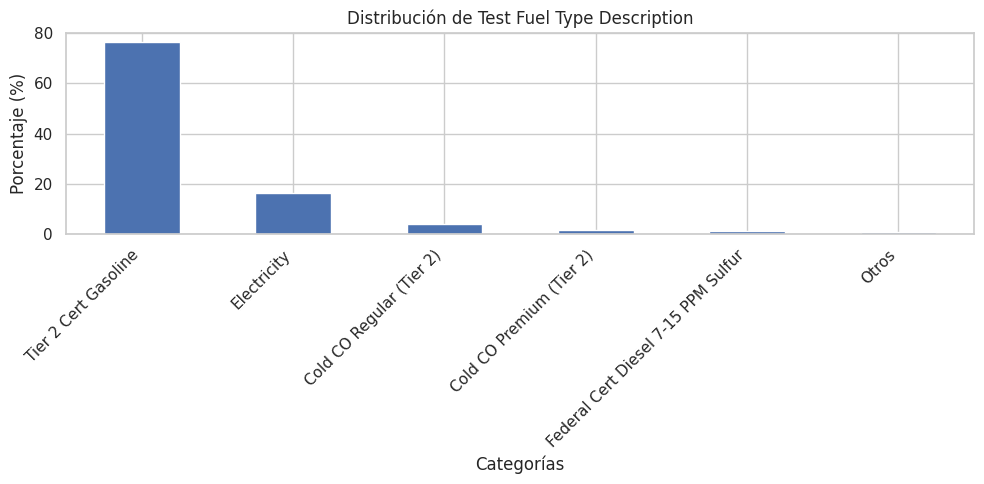

In [24]:
graficar_frecuencias('Test Fuel Type Description')

A partir del gráfico podemos observar que existe un claro predominio de la gasolina estándar (Tier 2 Cert Gasoline), que representa aproximadamente el 75,48 % de los registros. En segundo lugar, se encuentra la electricidad, con un 15,26 %, aunque con una participación considerablemente menor.

##### 1.1.7.2 Drive System Code

Código de tracción.

In [25]:
clean_df['Drive System Code'].value_counts()

Drive System Code
F    1376
A    1331
R     884
4     350
P      73
Name: count, dtype: int64

In [26]:
clean_df['Drive System Code'].info()

<class 'pandas.core.series.Series'>
RangeIndex: 4014 entries, 0 to 4013
Series name: Drive System Code
Non-Null Count  Dtype 
--------------  ----- 
4014 non-null   object
dtypes: object(1)
memory usage: 31.5+ KB


In [27]:
clean_df['Drive System Code'].isna().sum()

np.int64(0)

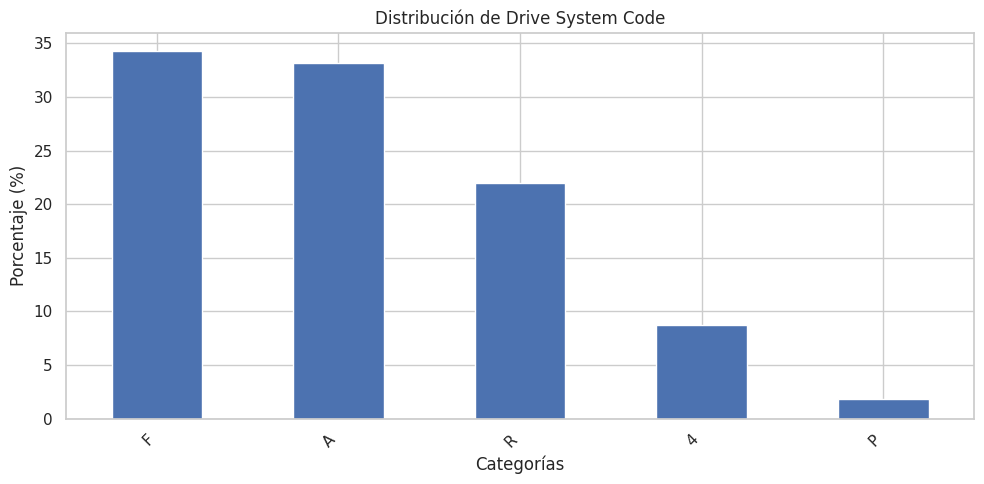

In [28]:
graficar_frecuencias('Drive System Code')

A partir del gráfico, podemos observar que los sistemas de tracción menos habituales son:
- P (Part-time 4WD): es el menos frecuente, con aproximadamente un 1,7 % de los registros. Corresponde a la tracción en las cuatro ruedas conectable.
- 4 (4WD): presenta una frecuencia cercana al 9,4 %, por lo que también tiene una participación considerablemente menor que los sistemas predominantes.

##### 1.1.7.3 Test Category

Categoría resumida del ensayo.

In [29]:
clean_df['Test Category'].value_counts()

Test Category
FTP     1466
HWY     1232
CD       687
US06     377
SC03     252
Name: count, dtype: int64

In [30]:
clean_df['Test Category'].info()

<class 'pandas.core.series.Series'>
RangeIndex: 4014 entries, 0 to 4013
Series name: Test Category
Non-Null Count  Dtype 
--------------  ----- 
4014 non-null   object
dtypes: object(1)
memory usage: 31.5+ KB


In [31]:
clean_df['Test Category'].isna().sum()

np.int64(0)

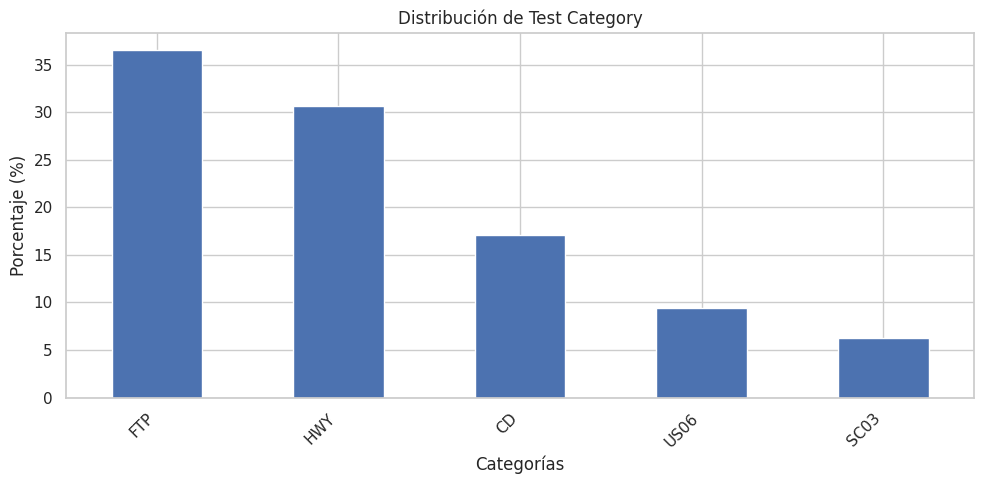

In [32]:
graficar_frecuencias('Test Category')

En general, todas las categorías cuentan con una representación considerable, por lo que no se identifican categorías con frecuencias extremadamente bajas.

##### 1.1.7.4 Vehicle Type

Car, Truck o Both.

In [33]:
clean_df['Vehicle Type'].value_counts()

Vehicle Type
Truck    1906
Car      1560
Both      548
Name: count, dtype: int64

In [34]:
clean_df['Vehicle Type'].info()

<class 'pandas.core.series.Series'>
RangeIndex: 4014 entries, 0 to 4013
Series name: Vehicle Type
Non-Null Count  Dtype 
--------------  ----- 
4014 non-null   object
dtypes: object(1)
memory usage: 31.5+ KB


In [35]:
clean_df['Vehicle Type'].isna().sum()

np.int64(0)

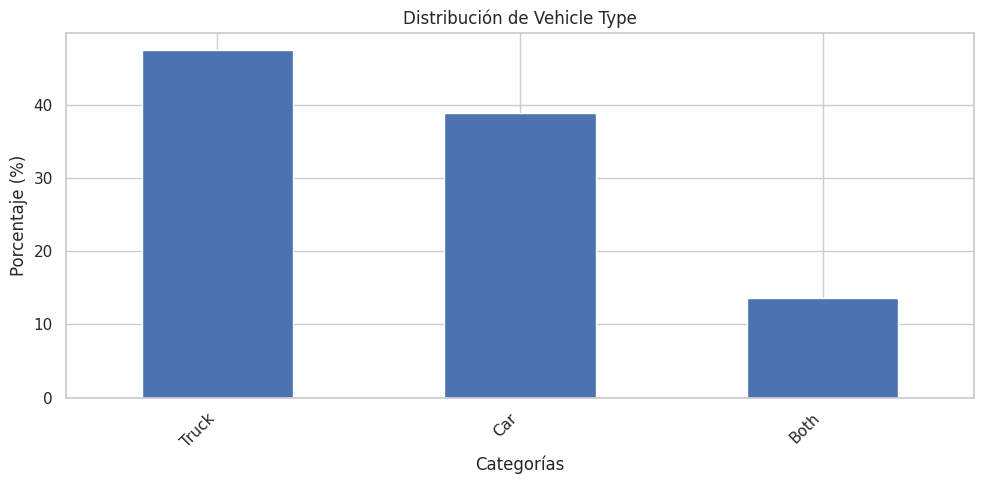

In [36]:
graficar_frecuencias('Vehicle Type')

##### 1.1.7.5 Tested Transmission Type

Automática, manual, semiautomática, CVT, etc.

In [37]:
clean_df['Tested Transmission Type'].value_counts()

Tested Transmission Type
Automatic                                                            1515
Semi-Automatic                                                       1130
Continuously Variable                                                 484
Automated Manual- Selectable (e.g. Automated Manual with paddles)     455
Selectable Continuously Variable (e.g. CVT with paddles)              171
Manual                                                                121
Other                                                                 102
Automated Manual                                                       36
Name: count, dtype: int64

In [38]:
clean_df['Tested Transmission Type'].info()

<class 'pandas.core.series.Series'>
RangeIndex: 4014 entries, 0 to 4013
Series name: Tested Transmission Type
Non-Null Count  Dtype 
--------------  ----- 
4014 non-null   object
dtypes: object(1)
memory usage: 31.5+ KB


In [39]:
clean_df['Tested Transmission Type'].isna().sum()

np.int64(0)

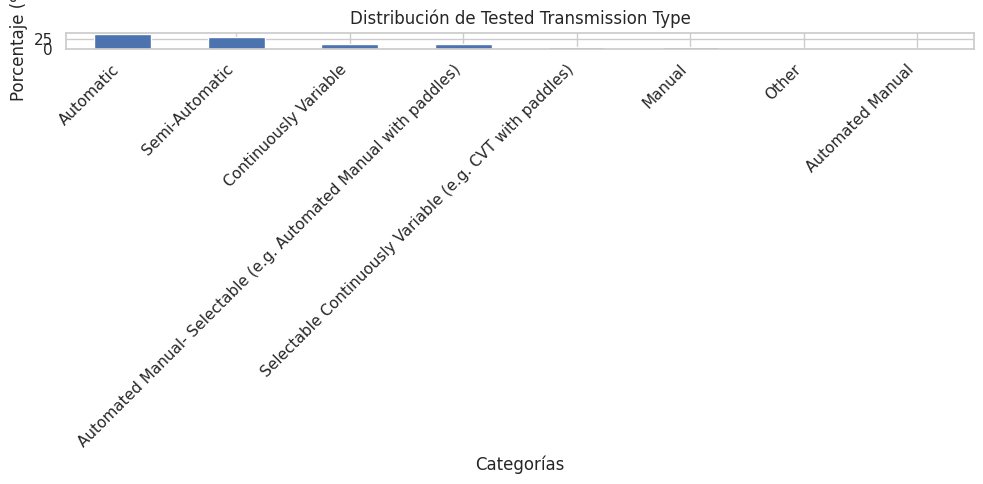

In [41]:
graficar_frecuencias('Tested Transmission Type')

A partir de los datos, podemos observar que los tipos de transmisión menos frecuentes son Automated Manual, con 52 registros (1,21 %), Other, con 102 registros (2,38 %), y Manual (tradicional), con 128 registros (2,99 %).

#### 1.1.8 Análisis de variables categóricas extras

##### 1.1.8.1 Vehicle Manufacturer Name

Fabricante del vehículo.

In [42]:
clean_df['Vehicle Manufacturer Name'].value_counts()

Vehicle Manufacturer Name
GM                      553
Toyota                  523
BMW                     499
Hyundai                 317
Volkswagen Group of     280
FOMOCO                  250
Mercedes-Benz           205
Nissan                  191
Kia                     167
Porsche                 152
Honda                   144
FCA US LLC              131
MAZDA                    82
Rivian Automotive L      77
Jaguar Land Rover L      77
Subaru                   68
Volvo                    67
Tesla                    43
Maserati                 31
Ferrari                  26
Mitsubishi Motors Co     25
Wuhan Lotus Cars Co      24
Lucid USA, Inc           20
Vinfast Trading and      20
Rolls-Royce              10
aston martin              8
Lotus                     8
Ineos Automotive Li       6
Karma Automotive          4
Bugatti Rimac LLC         2
CZV Inc                   2
Pagani S.p.A.             2
Name: count, dtype: int64

In [43]:
clean_df['Vehicle Manufacturer Name'].info()

<class 'pandas.core.series.Series'>
RangeIndex: 4014 entries, 0 to 4013
Series name: Vehicle Manufacturer Name
Non-Null Count  Dtype 
--------------  ----- 
4014 non-null   object
dtypes: object(1)
memory usage: 31.5+ KB


In [44]:
clean_df['Vehicle Manufacturer Name'].isna().sum()

np.int64(0)

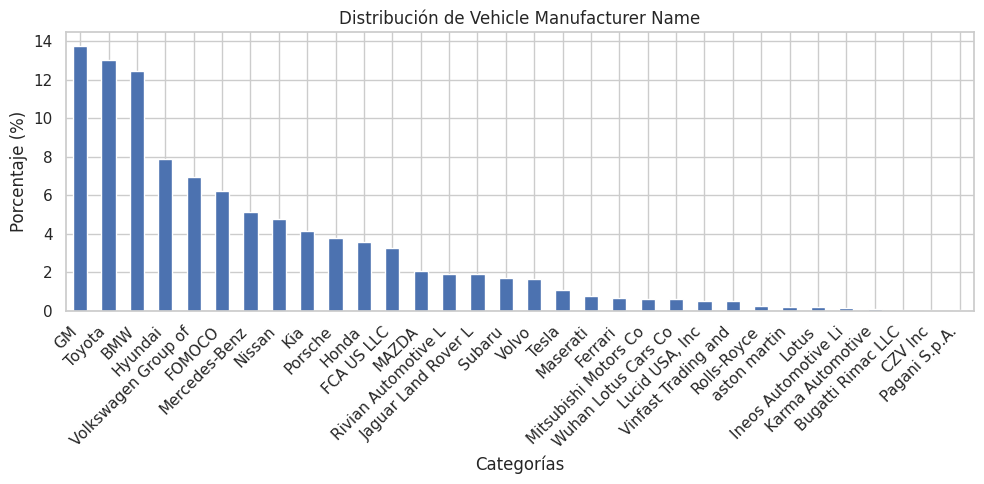

In [45]:
graficar_frecuencias('Vehicle Manufacturer Name')

Se observa una distribución desigual entre los fabricantes: mientras algunos concentran una gran cantidad de ensayos, otros tienen una representación muy reducida. Estos últimos pueden considerarse posibles outliers categóricos debido a su baja frecuencia dentro del dataset. Sin embargo, su escasa presencia no implica que los registros sean incorrectos, sino que corresponden a fabricantes con menor representación en la muestra.

##### 1.1.8.2 Engine Code

Código del motor.

In [46]:
clean_df['Engine Code'].value_counts()

Engine Code
01              212
1               193
03               92
02               91
2                74
               ... 
SCGWEJNG0003      1
GOTI              1
PA_1              1
EV_1              1
PB_1              1
Name: count, Length: 523, dtype: int64

In [47]:
clean_df['Engine Code'].info()

<class 'pandas.core.series.Series'>
RangeIndex: 4014 entries, 0 to 4013
Series name: Engine Code
Non-Null Count  Dtype 
--------------  ----- 
4014 non-null   object
dtypes: object(1)
memory usage: 31.5+ KB


In [48]:
clean_df['Engine Code'].isna().sum()

np.int64(0)

La variable Engine Code presenta una elevada cardinalidad, con 523 categorías distintas. Si bien algunos códigos concentran una mayor cantidad de registros, existe una gran cantidad de configuraciones de motor con frecuencias muy bajas, incluso de un único registro. Esta diversidad puede explicarse por la variedad de vehículos y fabricantes incluidos en el dataset. Por este motivo, no se considera que la presencia de numerosos códigos constituya un problema de calidad de datos por sí misma, aunque sí representa una dificultad para su análisis estadístico. No se recomienda eliminar estas categorías únicamente por su baja frecuencia, ya que podrían representar configuraciones de motor válidas y específicas.

#### 1.1.9 Análisis de variables numéricas de las hipótesis

In [49]:
import matplotlib.pyplot as plt

def graficar_boxplot(columna):
    plt.figure(figsize=(8, 4))

    clean_df.boxplot(column=columna)

    plt.title(f'Boxplot de {columna}')
    plt.ylabel(columna)
    plt.show()

##### 1.1.9.1 RND_ADJ_FE

Representa la **economía de combustible ajustada y redondeada del ensayo**, expresada en millas por galón (**MPG**).

In [50]:
clean_df['RND_ADJ_FE'].info()

<class 'pandas.core.series.Series'>
RangeIndex: 4014 entries, 0 to 4013
Series name: RND_ADJ_FE
Non-Null Count  Dtype 
--------------  ----- 
3801 non-null   object
dtypes: object(1)
memory usage: 31.5+ KB


In [51]:
clean_df['RND_ADJ_FE'].value_counts()

RND_ADJ_FE
33,6000000     15
34,1000000     15
999,0000000    14
36,7000000     14
38,2000000     12
               ..
92,0            1
100,0           1
54,2            1
13,5            1
45,4000000      1
Name: count, Length: 1171, dtype: int64

In [52]:
clean_df['RND_ADJ_FE'].describe()

count           3801
unique          1171
top       33,6000000
freq              15
Name: RND_ADJ_FE, dtype: object

Como notamos que hay valores que son extremos tomamos la decision de volverlos NaN. Ya que no tenia ningun sentido

In [53]:
# 1. Normalizar separador decimal (reemplazar comas por puntos)
clean_df["RND_ADJ_FE"] = clean_df["RND_ADJ_FE"].astype(str).str.replace(",", ".", regex=False)

# 2. Convertir a tipo de dato numérico (float)
clean_df["RND_ADJ_FE"] = pd.to_numeric(clean_df["RND_ADJ_FE"], errors="coerce")

# 2. Reemplazar únicamente códigos de error (ej. 999) y valores imposibles por NaN
clean_df.loc[
    (clean_df["RND_ADJ_FE"] <= 0)
    | (clean_df["RND_ADJ_FE"] == 999.0)
    | (clean_df["RND_ADJ_FE"] > 500),
    "RND_ADJ_FE",
] = np.nan

In [55]:
clean_df['RND_ADJ_FE'].isna().sum()

np.int64(239)

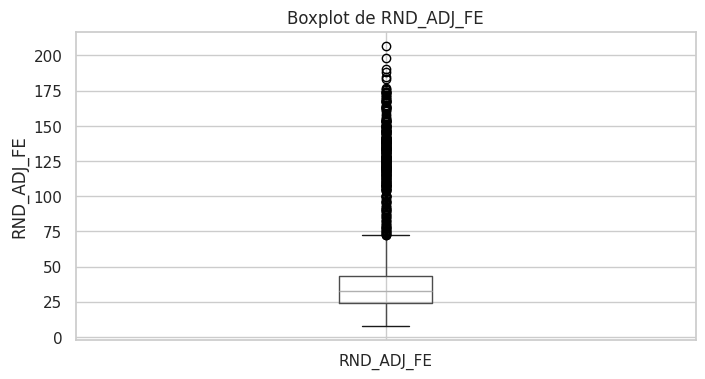

In [56]:
graficar_boxplot('RND_ADJ_FE')

##### 1.1.9.2 Equivalent Test Weight (lbs.)

representa el **peso equivalente de prueba del vehículo**, expresado en **libras (lb)**

In [57]:
clean_df['Equivalent Test Weight (lbs.)'].info()

<class 'pandas.core.series.Series'>
RangeIndex: 4014 entries, 0 to 4013
Series name: Equivalent Test Weight (lbs.)
Non-Null Count  Dtype
--------------  -----
4014 non-null   int64
dtypes: int64(1)
memory usage: 31.5 KB


In [58]:
clean_df['Equivalent Test Weight (lbs.)'].value_counts()

Equivalent Test Weight (lbs.)
5500    480
4250    395
4750    381
6000    372
5000    342
4500    308
4000    307
5250    268
6500    202
3875    195
3500    166
3750    133
3375    131
3625    110
7000     89
3250     60
3000     18
3125     13
7500     13
9000     12
8500      8
2875      4
2750      4
8000      3
Name: count, dtype: int64

In [59]:
clean_df['Equivalent Test Weight (lbs.)'].describe()

count    4014.000000
mean     4811.503488
std       989.182010
min      2750.000000
25%      4000.000000
50%      4750.000000
75%      5500.000000
max      9000.000000
Name: Equivalent Test Weight (lbs.), dtype: float64

In [60]:
clean_df['Equivalent Test Weight (lbs.)'].isna().sum()

np.int64(0)

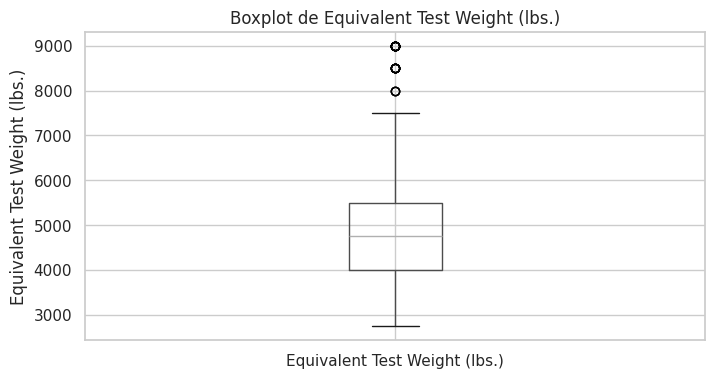

In [61]:
graficar_boxplot('Equivalent Test Weight (lbs.)')

In [62]:
# 1. Calcular cuartiles e IQR
q1 = clean_df['Equivalent Test Weight (lbs.)'].quantile(0.25)
q3 = clean_df['Equivalent Test Weight (lbs.)'].quantile(0.75)
iqr = q3 - q1

# 2. Calcular límites
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

# 3. Identificar valores atípicos
outliers = clean_df[
    (clean_df['Equivalent Test Weight (lbs.)'] < limite_inferior) |
    (clean_df['Equivalent Test Weight (lbs.)'] > limite_superior)
]

# 4. Mostrar resultados
print(f"Límite inferior: {limite_inferior}")
print(f"Límite superior: {limite_superior}")
print(f"Cantidad de outliers: {len(outliers)}")

# 5. Mostrar información de los vehículos
display(outliers[[
    'Vehicle Type',
    'Represented Test Veh Make',
    'Represented Test Veh Model',
    'Equivalent Test Weight (lbs.)',
    'Test Vehicle ID'
]].sort_values('Equivalent Test Weight (lbs.)', ascending=False))

Límite inferior: 1750.0
Límite superior: 7750.0
Cantidad de outliers: 23


,Vehicle Type,Represented Test Veh Make,Represented Test Veh Model,Equivalent Test Weight (lbs.),Test Vehicle ID
1257,Truck,CHEVROLET,SILVERADO EV,9000,2SE1E274
1256,Truck,CHEVROLET,SILVERADO EV,9000,2SE1E274
1255,Truck,CHEVROLET,SILVERADO EV,9000,2SE1E274
1261,Truck,CHEVROLET,SILVERADO EV,9000,2SE1E277
1260,Truck,CHEVROLET,SILVERADO EV,9000,2SE1E274
1259,Truck,CHEVROLET,SILVERADO EV,9000,2SE1E274
1258,Truck,CHEVROLET,SILVERADO EV,9000,2SE1E274
1460,Truck,GMC,SIERRA EV,9000,3SETE272
1373,Truck,GMC,HUMMER EV SUV,9000,HSSTC492
1369,Truck,GMC,HUMMER EV PICKUP,9000,HSSTB483


los valores atípicos identificados corresponden a vehículos clasificados como Truck, principalmente camionetas eléctricas de gran porte, como la Chevrolet Silverado EV, GMC Sierra EV y GMC Hummer EV. Sus elevados pesos de ensayo se justifican por las características propias de este tipo de vehículos. Por lo tanto, se decidió conservar estos registros, ya que no representan necesariamente errores en los datos, sino vehículos de mayor tamaño y peso que se alejan del comportamiento general del dataset.

##### 1.1.9.3 Target Coef A

##### 1.1.9.4 Test Veh Displacement (L)

Cilindrada del motor.

In [63]:
clean_df['Test Veh Displacement (L)'].info()

<class 'pandas.core.series.Series'>
RangeIndex: 4014 entries, 0 to 4013
Series name: Test Veh Displacement (L)
Non-Null Count  Dtype 
--------------  ----- 
4014 non-null   object
dtypes: object(1)
memory usage: 31.5+ KB


In [64]:
clean_df['Test Veh Displacement (L)'].value_counts()

Test Veh Displacement (L)
2,000     594
0,001     518
3,000     379
2,500     299
2,487     206
3,500     164
1,600     157
5,300     110
2,700     108
1,500     101
4,400      96
99,999     95
2,393      84
1,987      82
3,600      79
4,000      63
6,200      63
3,982      61
2,400      48
0,010      47
2,900      45
2,999      44
3,445      44
2,300      42
5,500      41
5,000      40
1,991      38
1,999      37
1,969      35
3,456      31
1,200      30
1,984      30
3,800      30
3,300      30
1,300      25
1,798      20
4,969      14
5,200      10
3,900      10
6,500       8
3,700       8
3,996       7
5,700       6
2,998       6
1,498       5
1,618       4
1,998       4
6,400       2
6,000       2
99,990      2
5,980       2
6,700       2
1,000       2
7,993       2
6,498       2
Name: count, dtype: int64

Notamos que la variable `Test Veh Displacement (L)` es de tipo str, asi que la cambiamos a tipo float. Hacemos esto porque esta variable representa la cilindrada del motor en litros, una magnitud numérica que puede contener valores decimales (por ejemplo, 1.5, 2.0 o 3.6).

Esto permite realizar correctamente operaciones matemáticas y análisis estadísticos, como calcular promedios, medianas y detectar valores atípicos.

In [65]:
# Normalizar separador decimal (reemplazar comas por puntos) y convertir a flotante
clean_df["Test Veh Displacement (L)"] = (clean_df["Test Veh Displacement (L)"].astype(str).str.replace(",", ".", regex=False))

# Convertir a tipo numérico (float)
clean_df["Test Veh Displacement (L)"] = pd.to_numeric(clean_df["Test Veh Displacement (L)"], errors="coerce")


In [66]:
clean_df["Test Veh Displacement (L)"].describe()

count    4014.000000
mean        4.801358
std        15.050234
min         0.001000
25%         1.987000
50%         2.487000
75%         3.300000
max        99.999000
Name: Test Veh Displacement (L), dtype: float64

Se identificaron dos valores extremadamente elevados en la variable Test Veh Displacement (L), correspondientes a 99.999 y 99.990 litros. Debido a que resultaban inconsistentes con las cilindradas habituales de los vehículos, se decidió reemplazarlos por valores faltantes (NaN) para evitar que distorsionaran los análisis estadísticos posteriores.

In [81]:
# Reemplazar valores extremos por NaN
valores_invalidos = [99.999, 99.990]

clean_df['Test Veh Displacement (L)'] = (clean_df['Test Veh Displacement (L)'].replace(valores_invalidos, np.nan))

In [82]:
clean_df['Test Veh Displacement (L)'].isna().sum()

np.int64(97)

Los nulos se deben a los valores extremos que eliminamos

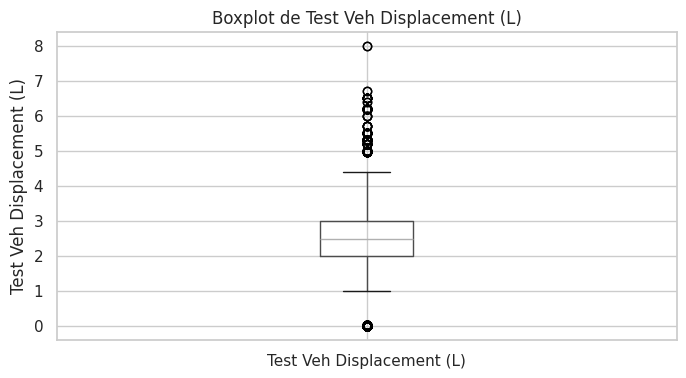

In [83]:
graficar_boxplot('Test Veh Displacement (L)')

##### 1.1.9.5 Rated Horsepower

Potencia nominal.

In [84]:
clean_df['Rated Horsepower'].info()

<class 'pandas.core.series.Series'>
RangeIndex: 4014 entries, 0 to 4013
Series name: Rated Horsepower
Non-Null Count  Dtype
--------------  -----
4014 non-null   int64
dtypes: int64(1)
memory usage: 31.5 KB


In [85]:
clean_df['Rated Horsepower'].value_counts()

Rated Horsepower
355     119
375     106
400     101
255      89
310      88
       ... 
1839      1
579       1
641       1
296       1
390       1
Name: count, Length: 244, dtype: int64

In [86]:
clean_df['Rated Horsepower'].describe()

count    4014.000000
mean      339.530144
std       176.546821
min         1.000000
25%       200.000000
50%       301.000000
75%       420.000000
max      1948.000000
Name: Rated Horsepower, dtype: float64

In [87]:
clean_df['Rated Horsepower'].isna().sum()

np.int64(0)

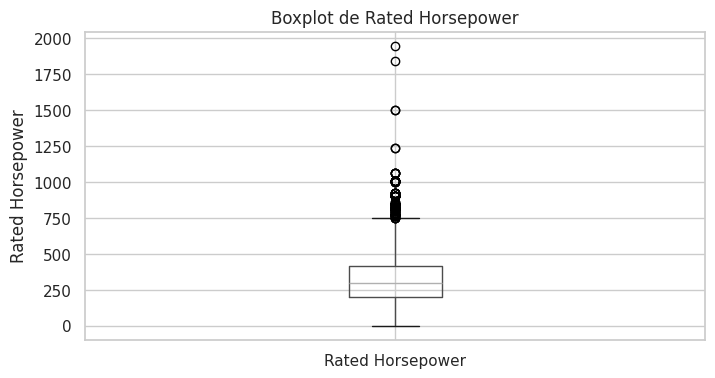

In [88]:
graficar_boxplot('Rated Horsepower')

In [89]:
# 1. Calcular cuartiles e IQR
q1 = clean_df['Rated Horsepower'].quantile(0.25)
q3 = clean_df['Rated Horsepower'].quantile(0.75)
iqr = q3 - q1

# 2. Calcular límites
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

# 3. Identificar valores atípicos
outliers = clean_df[
    (clean_df['Rated Horsepower'] < limite_inferior) |
    (clean_df['Rated Horsepower'] > limite_superior)
]

# 4. Mostrar resultados
print(f"Límite inferior: {limite_inferior}")
print(f"Límite superior: {limite_superior}")
print(f"Cantidad de outliers: {len(outliers)}")

# 5. Mostrar información de los vehículos
display(outliers[[
    'Vehicle Manufacturer Name',
    'Represented Test Veh Make',
    'Represented Test Veh Model',
    'Rated Horsepower',
    'Test Vehicle ID'
]].sort_values('Rated Horsepower', ascending=False))

Límite inferior: -130.0
Límite superior: 750.0
Cantidad de outliers: 125


,Vehicle Manufacturer Name,Represented Test Veh Make,Represented Test Veh Model,Rated Horsepower,Test Vehicle ID
508,Bugatti Rimac LLC,Bugatti Rimac,Nevera R,1948,V39B12RZXS5AB8001
507,Bugatti Rimac LLC,Bugatti Rimac,Nevera,1839,V39X22AZ9M3AB8004
3843,Volkswagen Group of,BUGATTI,Bugatti Pur Sport,1500,BG744-PT50 CHIRON R
3844,Volkswagen Group of,BUGATTI,Bugatti Pur Sport,1500,BG744-PT50 CHIRON R
2194,"Lucid USA, Inc",2024,Air Sapphire AWD,1234,202400084
...,...,...,...,...,...
2900,Porsche,Porsche,Taycan Turbo S Cross Turismo,764,FE-YATSCUV-25
2215,Maserati,Maserati,Grancabrio Folgore,751,436805
2214,Maserati,Maserati,Grancabrio Folgore,751,436805
2220,Maserati,Maserati,Granturismo Folgore,751,436805


Mediante el método del rango intercuartílico (IQR), se identificaron 141 posibles valores atípicos en la variable Rated Horsepower. El límite inferior obtenido fue de -111 HP y el superior de 721 HP. Al investigar los registros con mayores potencias, se encontraron vehículos deportivos y eléctricos de altas prestaciones, como Bugatti Nevera R, Bugatti Chiron Pur Sport y Lucid Air Sapphire. Esto demuestra que algunos valores identificados como atípicos responden a características reales de determinados vehículos y no necesariamente a errores de carga. Por este motivo, se decidió no reemplazarlos automáticamente por valores faltantes.

#### 1.1.10 Análisis de variables numéricas extras

##### # of Gears

Representa la **cantidad de marchas** de la transmisión del vehículo.

In [90]:
clean_df['# of Gears'].info()

<class 'pandas.core.series.Series'>
RangeIndex: 4014 entries, 0 to 4013
Series name: # of Gears
Non-Null Count  Dtype
--------------  -----
4014 non-null   int64
dtypes: int64(1)
memory usage: 31.5 KB


In [91]:
clean_df['# of Gears'].value_counts()

# of Gears
8     1385
1     1224
10     439
9      340
6      329
7      259
2       36
5        2
Name: count, dtype: int64

In [92]:
clean_df['# of Gears'].describe()

count    4014.000000
mean        5.885152
std         3.422564
min         1.000000
25%         1.000000
50%         8.000000
75%         8.000000
max        10.000000
Name: # of Gears, dtype: float64

In [93]:
clean_df['# of Gears'].isna().sum()

np.int64(0)

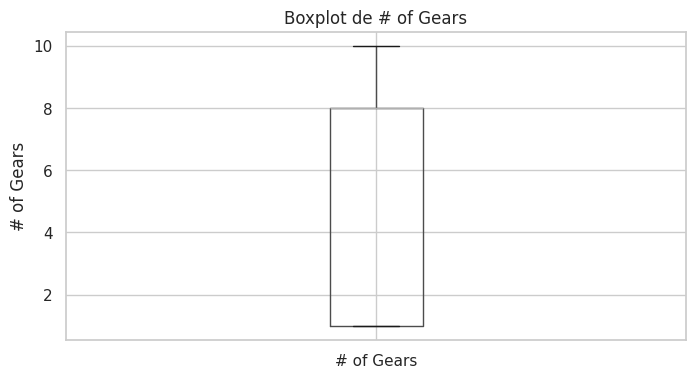

In [94]:
graficar_boxplot('# of Gears')

##### N/V Ratio

Es un parámetro mecánico del ensayo que representa la relación entre la velocidad de giro del motor (\\(N\\), en revoluciones) y la velocidad del vehículo (\\(V\\)).

In [156]:
clean_df['N/V Ratio'].info()

<class 'pandas.Series'>
RangeIndex: 4287 entries, 0 to 4286
Series name: N/V Ratio
Non-Null Count  Dtype  
--------------  -----  
4287 non-null   float64
dtypes: float64(1)
memory usage: 33.6 KB


Notamos que es de tipo str, la convertimos en float.

In [155]:
# Normalizar separador decimal (reemplazar comas por puntos) y convertir a flotante
clean_df["N/V Ratio"] = (clean_df["N/V Ratio"].astype(str).str.replace(",", ".", regex=False))

# Convertir a tipo numérico (float)
clean_df["N/V Ratio"] = pd.to_numeric(clean_df["N/V Ratio"], errors="coerce")

In [157]:
clean_df['N/V Ratio'].value_counts()

N/V Ratio
24.0     176
21.7      92
999.0     91
21.6      82
26.1      77
        ... 
107.5      1
100.8      1
144.4      1
144.2      1
142.2      1
Name: count, Length: 280, dtype: int64

In [166]:
clean_df['N/V Ratio'].describe()

count    4196.000000
mean       36.951859
std        32.577028
min         0.000000
25%        23.300000
50%        25.600000
75%        29.300000
max       229.200000
Name: N/V Ratio, dtype: float64

In [163]:
# Filtrar registros con Axle Ratio igual a 999.00
registros_999 = clean_df[
    clean_df['N/V Ratio'] == 999.00
]

# Mostrar información de los vehículos
display(registros_999[[
    'Vehicle Manufacturer Name',
    'Represented Test Veh Make',
    'Represented Test Veh Model',
    'Vehicle Type',
    'N/V Ratio',
    'Test Vehicle ID',
    'Test Number',
    'Tested Transmission Type',
    'Axle Ratio',
    '# of Gears'
]])

,Vehicle Manufacturer Name,Represented Test Veh Make,Represented Test Veh Model,Vehicle Type,N/V Ratio,Test Vehicle ID,Test Number,Tested Transmission Type,Axle Ratio,# of Gears
2483,"Lucid USA, Inc",2025,Lucid Gravity GT (2R),Car,999.0,2025G01033,SLMU10088423,Automatic,7.06,1
2484,"Lucid USA, Inc",2025,Lucid Gravity GT (2R),Car,999.0,2025G01033,SLMU10088082,Automatic,7.06,1
2485,"Lucid USA, Inc",2025,Lucid Gravity GT (3R),Car,999.0,2025G01034,SLMU10088084,Automatic,7.06,1
2486,"Lucid USA, Inc",2025,Lucid Gravity GT (3R),Car,999.0,2025G01034,SLMU10088083,Automatic,7.06,1
2487,Maserati,Maserati,Grancabrio Folgore,Car,999.0,436805,SMAX10086837,Other,6.92,1
...,...,...,...,...,...,...,...,...,...,...
3247,Rivian Automotive L,Rivian,R1T Performance Dual Max (22in),Truck,999.0,R1T240XR22,SRIV10086075,Automatic,NaN,1
3248,Rivian Automotive L,Rivian,R1T Performance Dual Max (22in),Truck,999.0,R1T240XR22,SRIV10086076,Automatic,NaN,1
3249,Rivian Automotive L,Rivian,R1T Performance Dual Max (22in),Truck,999.0,R1T240XR22,SRIV10086077,Automatic,NaN,1
3250,Rivian Automotive L,Rivian,R1T Performance Dual Max (22in),Truck,999.0,R1T240XR22,SRIV10086078,Automatic,NaN,1


Durante el análisis de la variable N/V Ratio, se identificó el valor 999 como un posible código especial, debido a que se encuentra muy alejado de los valores habituales de la variable. Al investigar los registros asociados, se observó que aparece en vehículos eléctricos de distintos fabricantes, como Lucid, Maserati y Rivian, que presentan una única marcha. Esto sugiere que podría tratarse de un valor utilizado para representar una relación no disponible o no aplicable. Por este motivo, se decidió investigar su significado en la metadata antes de determinar su reemplazo por un valor faltante (NaN).

In [164]:
# Reemplazar el valor 999.00 por NaN
clean_df['N/V Ratio'] = (clean_df['N/V Ratio'].replace(999.00, np.nan))

In [165]:
clean_df['N/V Ratio'].isna().sum()

np.int64(91)

KeyError: "None of [Index(['N/V Ratio'], dtype='str')] are in the [columns]"

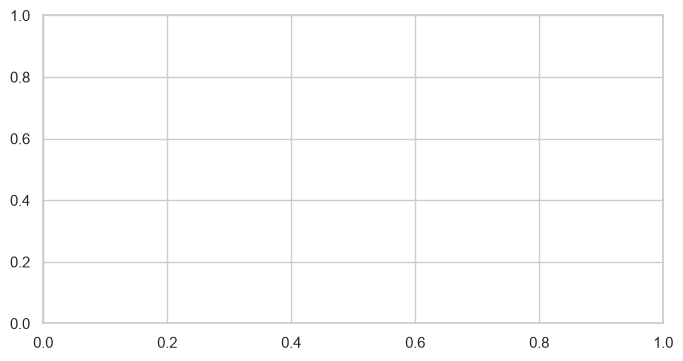

In [6]:
graficar_boxplot('N/V Ratio')

##### Axle Ratio

Es un parámetro mecánico del ensayo que representa la **relación de eje**.

In [140]:
clean_df['Axle Ratio'].info()

<class 'pandas.Series'>
RangeIndex: 4287 entries, 0 to 4286
Series name: Axle Ratio
Non-Null Count  Dtype  
--------------  -----  
4287 non-null   float64
dtypes: float64(1)
memory usage: 33.6 KB


In [148]:
clean_df['Axle Ratio'].value_counts()

Axle Ratio
3.23    340
1.00    266
2.81    129
3.42     98
3.73     95
       ... 
4.30      2
3.04      2
9.20      2
2.58      2
2.55      2
Name: count, Length: 161, dtype: int64

Notamos que la variable `Axle Ratio` es de tipo str, asi que la cambiamos a tipo float.Hacemos esto porque es una variable que contiene valores decimales. Este cambio permite realizar operaciones matemáticas y análisis estadísticos, como calcular promedios, medianas y detectar posibles valores atípicos.

In [139]:
# Normalizar separador decimal (reemplazar comas por puntos) y convertir a flotante
clean_df["Axle Ratio"] = (clean_df["Axle Ratio"].astype(str).str.replace(",", ".", regex=False))

# Convertir a tipo numérico (float)
clean_df["Axle Ratio"] = pd.to_numeric(clean_df["Axle Ratio"], errors="coerce")

In [149]:
clean_df['Axle Ratio'].describe()

count    4169.000000
mean        3.608801
std         1.384319
min         0.000000
25%         3.200000
50%         3.420000
75%         3.800000
max         9.810000
Name: Axle Ratio, dtype: float64

Analizando el valor maximo:

In [144]:
# Filtrar registros con Axle Ratio igual a 9.99
registros_999 = clean_df[
    clean_df['Axle Ratio'] == 9.99
]

# Mostrar información de los vehículos
display(registros_999[[
    'Vehicle Manufacturer Name',
    'Represented Test Veh Make',
    'Represented Test Veh Model',
    'Vehicle Type',
    'Axle Ratio',
    'Test Vehicle ID'
]])

,Vehicle Manufacturer Name,Represented Test Veh Make,Represented Test Veh Model,Vehicle Type,Axle Ratio,Test Vehicle ID
636,FCA US LLC,Dodge,Charger 2-Dr Daytona R/T AWD 20in Nexen,Car,9.99,N4LB75749
637,FCA US LLC,Dodge,Charger 2-Dr Daytona Scat Pack Track Pack AWD A/S,Car,9.99,N4LB75563
703,FCA US LLC,Jeep,Wagoneer S AWD (Falken tire),Both,9.99,N4KMX1858
3175,Rivian Automotive L,Rivian,R1S All-Terrain Performance Dual Large (20in),Truck,9.99,R1S378XR20AT
3176,Rivian Automotive L,Rivian,R1S All-Terrain Performance Dual Large (20in),Truck,9.99,R1S378XR20AT
...,...,...,...,...,...,...
4214,Volvo,Polestar,Polestar 4 long range single motor,Car,9.99,202533
4219,Volvo,Volvo,EX30 Single Motor extended range,Car,9.99,202532
4220,Volvo,Volvo,EX30 Single Motor extended range(18 Inch Wheel),Car,9.99,202532
4221,Volvo,Volvo,EX30 Twin Performance (19 Inch Wheels),Car,9.99,202536


Se identificó que el valor 9,99 aparece en 118 registros de la variable Axle Ratio, correspondientes a distintos fabricantes, modelos y tipos de vehículos. Debido a su elevada frecuencia y a su presencia en configuraciones muy diversas, se sospecha que podría tratarse de un código que representa información no disponible o no aplicable.

In [145]:
# Reemplazar el valor 9.99 por NaN
clean_df['Axle Ratio'] = (clean_df['Axle Ratio'].replace(9.99, np.nan))

In [146]:
clean_df['Axle Ratio'].isna().sum()

np.int64(118)

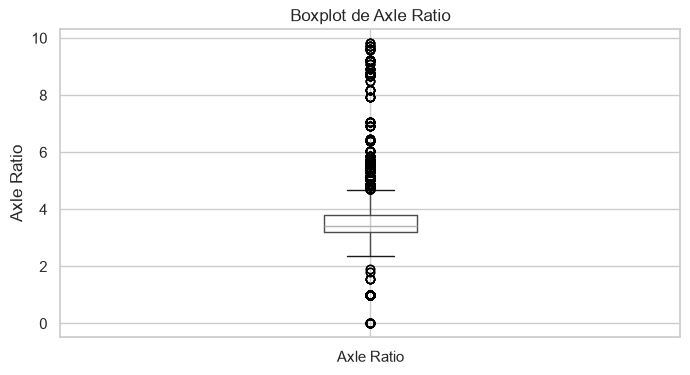

In [147]:
graficar_boxplot('Axle Ratio')

##### # of Cylinders and Rotors

Número de cilindros o rotores.

In [119]:
clean_df['# of Cylinders and Rotors'].info()

<class 'pandas.Series'>
RangeIndex: 4287 entries, 0 to 4286
Series name: # of Cylinders and Rotors
Non-Null Count  Dtype  
--------------  -----  
3617 non-null   float64
dtypes: float64(1)
memory usage: 33.6 KB


In [120]:
clean_df['# of Cylinders and Rotors'].value_counts()

# of Cylinders and Rotors
4.0     1903
6.0     1048
8.0      544
3.0       89
12.0      26
5.0        5
16.0       2
Name: count, dtype: int64

In [121]:
clean_df['# of Cylinders and Rotors'].describe()

count    3617.000000
mean        5.222007
std         1.624339
min         3.000000
25%         4.000000
50%         4.000000
75%         6.000000
max        16.000000
Name: # of Cylinders and Rotors, dtype: float64

In [122]:
clean_df['# of Cylinders and Rotors'].isna().sum()

np.int64(670)

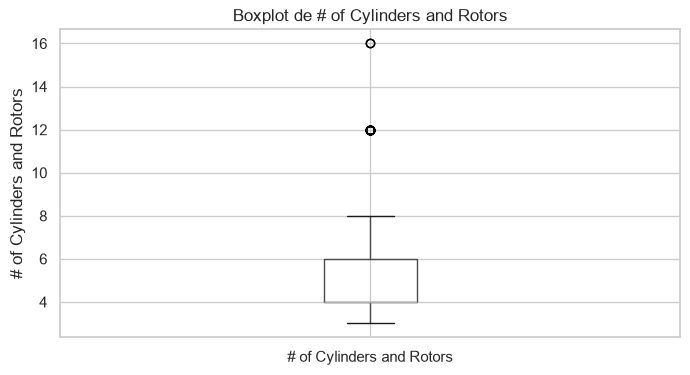

In [123]:
graficar_boxplot('# of Cylinders and Rotors')

## 1.2 Eliminación de columnas 

#### 1.2.1 Columnas sin variabilidad

Se eliminan las columnas `Model Year` y `FE_UNIT` del dataset.

**Justificación:** Ambas columnas presentan un único valor constante (2025 y MPG, respectivamente), por lo que tienen varianza nula y no aportan información útil para el análisis.

In [95]:
# Eliminación de columnas sin variabilidad
clean_df = clean_df.drop(columns=['Model Year', 'FE_UNIT'])

#### 1.2.2 Columnas con mucho porcentaje de nulos

In [96]:
#Eliminación de columnas por gran porcentaje de nulos (datos no útiles)
# ADFE solo 212 valores no nulos, más del 95% son valores nulos
clean_df = clean_df.drop(columns=['ADFE Test Number','ADFE Total Road Load HP','ADFE Equiv. Test Weight (lbs.)','ADFE N/V Ratio'])
# más del 90% de nulos
clean_df = clean_df.drop(columns=['FE Bag 4','PM (g/mi)'])
# más del 98% de nulos
clean_df = clean_df.drop(columns = ['Averaging Group ID', 'Averaging Weighting Factor'])

# REVISAR DONDE PONEMOS UMBRAL PARA PORC DE NULOS -->'FE Bag 3 tienen mas del 65%
#CHEQUEAR QUE NINGUNA SEA SIGNIFICATIVA

In [97]:
cant_actual = clean_df.shape[1]
anterior = df.shape[1]
diferencia = anterior - cant_actual
print(f"Hay {cant_actual} columnas en el dataset luego de la eliminación de las columnas no representativas por tener gran cantidad de nulos o ser constantes. Se eliminaron {diferencia} columnas")

Hay 57 columnas en el dataset luego de la eliminación de las columnas no representativas por tener gran cantidad de nulos o ser constantes. Se eliminaron 10 columnas


## 1.3 Busqueda de nulos no estandarizados

In [98]:
# 1. Búsqueda de nulos no estandarizados en columnas tipo object
print("Valores sospechosos en variables de texto:")
for col in df.select_dtypes(include='object').columns:
    sospechosos = df[col].isin(['-1', 'Unknown', 'Unknown / Non-Applicable', 'N/A', '']).sum()
    if sospechosos > 0:
        print(f" - {col}: {sospechosos} registros")

# 2. Control de filas duplicadas exactas
print("\nFilas exactamente duplicadas en la base:", df.duplicated().sum())

# 3. Inspección de la clave única de vehículo
clave_vehiculo = ['Veh Mfr Code', 'Test Vehicle ID', 'Test Veh Configuration #']
configuraciones_unicas = df.groupby(clave_vehiculo).ngroups
print("Cantidad de configuraciones únicas de vehículos:", configuraciones_unicas)
print("Cantidad total de ensayos registrados:", len(df))

Valores sospechosos en variables de texto:

Filas exactamente duplicadas en la base: 0
Cantidad de configuraciones únicas de vehículos: 1448
Cantidad total de ensayos registrados: 4287


# 2. Validación de Hipótesis

## 2.1 Validación de Hipótesis Univariadas

### 2.1.1 Test Fuel Type Description

In [99]:
import statsmodels.stats.proportion as prop

# 1. Conteo de ensayos
total_ensayos = len(clean_df)
tier2_count = (clean_df['Test Fuel Type Description'] == 'Tier 2 Cert Gasoline').sum()
prop_observada = tier2_count / total_ensayos

print(f"Ensayos totales: {total_ensayos}")
print(f"Ensayos Tier 2: {tier2_count} ({prop_observada*100:.2f}%)")

# 2. Test Z de proporción (unilateral derecha: alternative='larger')
z_stat, p_value = prop.proportions_ztest(
    count=tier2_count, 
    nobs=total_ensayos, 
    value=0.60, 
    alternative='larger'
)

print(f"Estadístico Z: {z_stat:.4f}")
print(f"p-valor: {p_value:.4e}")

Ensayos totales: 4014
Ensayos Tier 2: 3064 (76.33%)
Estadístico Z: 24.3457
p-valor: 3.2228e-131


Los resultados muestran que 3.236 de los 4.287 ensayos registrados (75,48%) corresponden a Tier 2 Cert Gasoline. Mediante un test Z unilateral para una proporción, se obtuvo un estadístico Z de 23,5672 y un p-valor de 4,1805 × 10⁻¹²³. Dado que el p-valor es inferior al nivel de significancia del 5%, se rechaza la hipótesis nula. Por lo tanto, existe evidencia estadística suficiente para afirmar que la proporción de ensayos correspondientes a gasolina certificada Tier 2 supera el 60%.

A continuacion, se puede ver un grafico de barras de proporciones, con una linea de referencia horizontal en el 60%

/tmp/ipykernel_40760/4012693899.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=df_prop, x='Combustible', y='Porcentaje', palette='Blues_d')


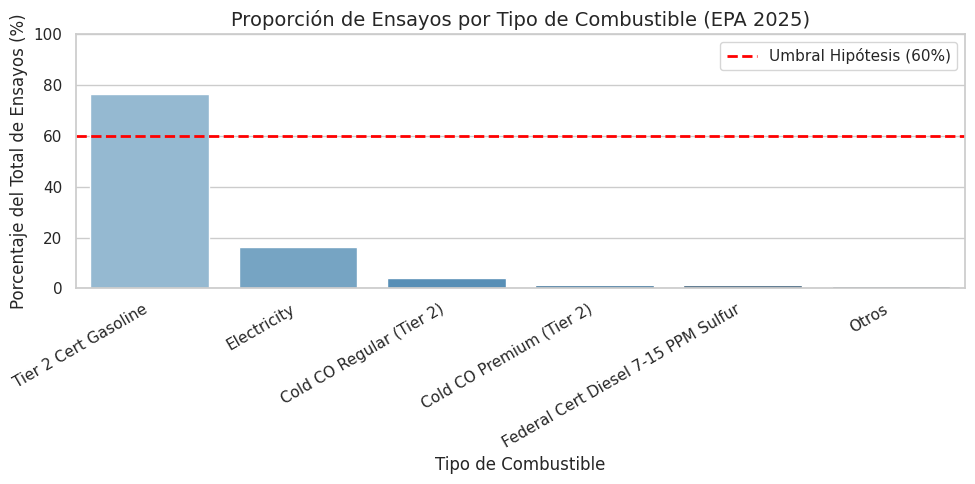

In [100]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Calcular porcentajes por tipo de combustible
df_prop = (clean_df['Test Fuel Type Description']
           .value_counts(normalize=True) * 100).reset_index()
df_prop.columns = ['Combustible', 'Porcentaje']

# 2. Crear gráfico de barras
plt.figure(figsize=(10, 5))
ax = sns.barplot(data=df_prop, x='Combustible', y='Porcentaje', palette='Blues_d')

# 3. Agregar la línea umbral del 60% (Hipótesis)
plt.axhline(y=60, color='red', linestyle='--', linewidth=2, label='Umbral Hipótesis (60%)')

# 4. Formato y etiquetas
plt.title('Proporción de Ensayos por Tipo de Combustible (EPA 2025)', fontsize=14)
plt.xlabel('Tipo de Combustible')
plt.ylabel('Porcentaje del Total de Ensayos (%)')
plt.ylim(0, 100) # Rango teórico completo
plt.xticks(rotation=30, ha='right')
plt.legend()
plt.tight_layout()
plt.show()

### 2.1.2 RND_ADJ_FE

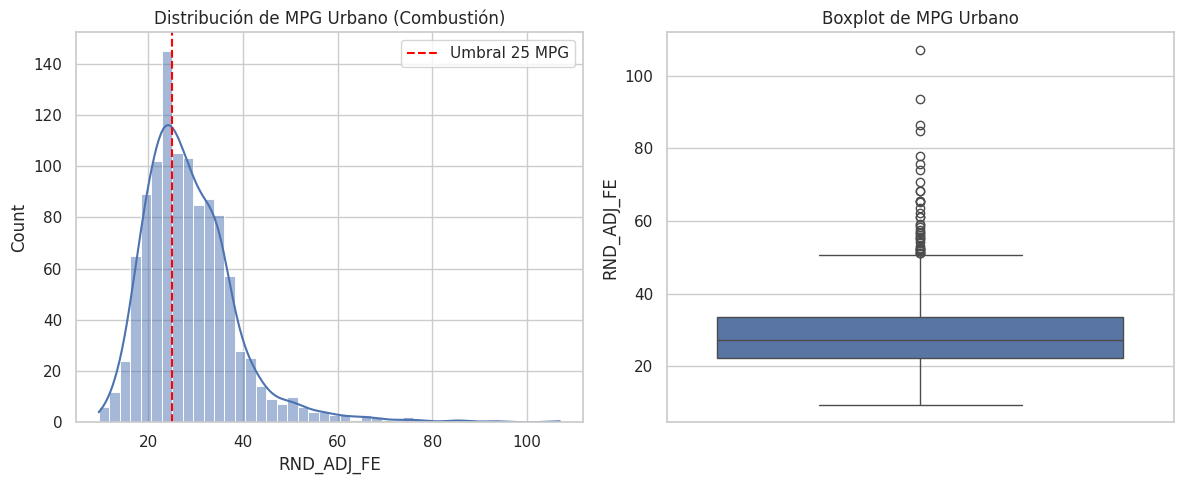

Test de Shapiro-Wilk: W=0.8732, p-valor=7.9564e-29
Configuraciones evaluadas: 1088 | Alcanzan >= 25 MPG: 651 (59.83%)
Estadístico Z: 6.6171 | p-valor: 1.8317e-11
Resultado del estudio: CONFIRMADA (Existe evidencia de que la mayoría alcanza al menos 25 MPG)


In [101]:

import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import shapiro
from statsmodels.stats.proportion import proportions_ztest

# 1. Filtrado de datos: vehículos a combustión y ciclo urbano (FTP)
cols_config = ["Veh Mfr Code", "Test Vehicle ID", "Test Veh Configuration #"]

df_combustion = clean_df[
    ~clean_df["Test Fuel Type Description"].str.contains("Electricity", na=False)
].copy()

if "Test Category" in df_combustion.columns:
    df_urbano = df_combustion[
        df_combustion["Test Category"].str.contains("FTP|City", na=False)
    ].copy()
else:
    df_urbano = df_combustion.copy()

# Deduplicación por configuración única
df_config_urbana = df_urbano.drop_duplicates(
    subset=cols_config
).dropna(subset=["RND_ADJ_FE"])

# 2. Análisis exploratorio gráfico y de normalidad
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(df_config_urbana["RND_ADJ_FE"], kde=True, ax=axes[0])
axes[0].set_title("Distribución de MPG Urbano (Combustión)")
axes[0].axvline(25, color="red", linestyle="--", label="Umbral 25 MPG")
axes[0].legend()

sns.boxplot(y=df_config_urbana["RND_ADJ_FE"], ax=axes[1])
axes[1].set_title("Boxplot de MPG Urbano")

plt.tight_layout()
plt.show()

# Test de normalidad Shapiro-Wilk
stat_shapiro, p_shapiro = shapiro(df_config_urbana["RND_ADJ_FE"])

print(
    f"Test de Shapiro-Wilk: W={stat_shapiro:.4f}, "
    f"p-valor={p_shapiro:.4e}"
)

# 3. Construcción de variable dicotómica y Test Z de una proporción
exitos = (df_config_urbana["RND_ADJ_FE"] >= 25).sum()
total = len(df_config_urbana)

if total > 0:
    p_hat = exitos / total
    

    # Test Z unilateral derecho (proporción de referencia = 0.50)
    z_stat, p_valor = proportions_ztest(
        count=exitos,
        nobs=total,
        value=0.50,
        alternative="larger"
    )

    print(
        f"Configuraciones evaluadas: {total} | "
        f"Alcanzan >= 25 MPG: {exitos} ({p_hat*100:.2f}%)"
    )
    print(f"Estadístico Z: {z_stat:.4f} | p-valor: {p_valor:.4e}")

    # 4. Validación de la hipótesis
    alpha = 0.05

    if p_valor < alpha and p_hat > 0.50:
        print(
            "Resultado del estudio: CONFIRMADA "
            "(Existe evidencia de que la mayoría alcanza al menos 25 MPG)"
        )
    else:
        print(
            "Resultado del estudio: NO CONFIRMADA "
            "(No hay evidencia suficiente para afirmar que la mayoría alcanza 25 MPG)"
        )
else:
    print("No hay configuraciones válidas para realizar el análisis.")


## 2.2 Validación de Hipótesis Bivariadas

### 2.2.1 RND_ADJ_FE y Test Category

In [102]:
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Filtrar vehículos a combustión (excluyendo eléctricos)
df_comb = clean_df[
    clean_df["Test Fuel Type Description"] != "Electricity"
].copy()

# 2. Filtrar ensayos por categoría (FTP = Ciudad, HWY = Carretera)
df_city = df_comb[
    df_comb["Test Category"] == "FTP"
][["Test Vehicle ID", "RND_ADJ_FE"]].rename(
    columns={"RND_ADJ_FE": "FE_City"}
)

df_hwy = df_comb[
    df_comb["Test Category"] == "HWY"
][["Test Vehicle ID", "RND_ADJ_FE"]].rename(
    columns={"RND_ADJ_FE": "FE_Hwy"}
)

# 3. Aparear observaciones por ID del vehículo
df_paired = pd.merge(
    df_city,
    df_hwy,
    on="Test Vehicle ID"
).dropna()

df_paired["Diferencia"] = df_paired["FE_Hwy"] - df_paired["FE_City"]

# 4. Validar normalidad de las diferencias (Shapiro-Wilk)
if len(df_paired) < 3:
    print("No hay suficientes observaciones para realizar el análisis.")
else:
    stat_sh, p_shapiro = stats.shapiro(df_paired["Diferencia"])

    print(
        f"Shapiro-Wilk (Diferencias): "
        f"Estadístico={stat_sh:.4f}, p-valor={p_shapiro:.4e}"
    )

    # 5. Aplicar prueba correspondiente
    if p_shapiro > 0.05:
        print("No se rechaza normalidad. Aplicando Paired t-test...")

        stat_t, p_val = stats.ttest_rel(
            df_paired["FE_Hwy"],
            df_paired["FE_City"],
            alternative="greater"
        )

        estadistico = stat_t

    else:
        print("Se rechaza normalidad. Aplicando Test de Wilcoxon...")

        stat_w, p_val = stats.wilcoxon(
            df_paired["FE_Hwy"],
            df_paired["FE_City"],
            alternative="greater"
        )

        estadistico = stat_w

    print(f"Estadístico de prueba: {estadistico:.4f}")
    print(f"p-valor final: {p_val:.4e}")

    # 6. Validación de la hipótesis
    alpha = 0.05

    if p_val < alpha:
        print(
            "Resultado: EXISTE EVIDENCIA ESTADÍSTICA "
            "DE QUE EL MPG EN CARRETERA ES MAYOR QUE EN CIUDAD."
        )
    else:
        print(
            "Resultado: NO EXISTE EVIDENCIA ESTADÍSTICA "
            "SUFICIENTE PARA AFIRMAR QUE EL MPG EN CARRETERA "
            "ES MAYOR QUE EN CIUDAD."
        )

Shapiro-Wilk (Diferencias): Estadístico=0.9346, p-valor=8.7043e-35
Se rechaza normalidad. Aplicando Test de Wilcoxon...
Estadístico de prueba: 4714799.5000
p-valor final: 0.0000e+00
Resultado: EXISTE EVIDENCIA ESTADÍSTICA DE QUE EL MPG EN CARRETERA ES MAYOR QUE EN CIUDAD.


In [105]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_melted,
    x="Condición",
    y="MPG",
    hue="Condición",
    palette=["#1f77b4", "#ff7f0e"],
    legend=False,
    width=0.4
)

plt.title("Comparación del rendimiento: Ciudad vs. Carretera")
plt.xlabel("Condición de manejo")
plt.ylabel("Rendimiento de combustible (MPG)")
plt.tight_layout()
plt.show()

NameError: name 'df_melted' is not defined

<Figure size 800x500 with 0 Axes>

### 2.2.2 RND_ADJ_FE y Drive System Code

In [106]:
import pandas as pd
import scipy.stats as stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd

# 1. Filtrar vehículos de combustión y eliminar valores nulos
df_comb = clean_df[
    (clean_df["Test Fuel Type Description"] != "Electricity") &
    (clean_df["Drive System Description"].notna()) &
    (clean_df["RND_ADJ_FE"].notna())
].copy()

# 2. Obtener grupos de tracción con al menos 10 observaciones
grupos_traccion = []
nombres_grupos = []

for nombre, grupo in df_comb.groupby("Drive System Description"):
    if len(grupo) >= 10:
        grupos_traccion.append(grupo["RND_ADJ_FE"].values)
        nombres_grupos.append(nombre)

# 3. Verificar que existan al menos dos grupos
if len(grupos_traccion) < 2:
    print("No hay suficientes grupos para realizar la comparación.")

else:
    # 4. Validación de homocedasticidad (Test de Levene)
    stat_lev, p_levene = stats.levene(*grupos_traccion)

    print("--- Test de Levene ---")
    print(f"Estadístico: {stat_lev:.4f}")
    print(f"p-valor: {p_levene:.4e}")

    # 5. Evaluación de la hipótesis global
    if p_levene > 0.05:
        f_stat, p_val = stats.f_oneway(*grupos_traccion)

        print("\n--- ANOVA de un factor ---")
        print(f"Estadístico F: {f_stat:.4f}")
        print(f"p-valor: {p_val:.4e}")

    else:
        h_stat, p_val = stats.kruskal(*grupos_traccion)

        print("\n--- Test de Kruskal-Wallis ---")
        print(f"Estadístico H: {h_stat:.4f}")
        print(f"p-valor: {p_val:.4e}")

    # 6. Comparaciones múltiples Post-Hoc
    if p_val < 0.05:
        print("\n--- Comparaciones a posteriori ---")

        df_filtrado = df_comb[
            df_comb["Drive System Description"].isin(nombres_grupos)
        ]

        tukey = pairwise_tukeyhsd(
            endog=df_filtrado["RND_ADJ_FE"],
            groups=df_filtrado["Drive System Description"],
            alpha=0.05
        )

        print(tukey)

    else:
        print("\nNo se encontraron diferencias estadísticamente significativas.")

--- Test de Levene ---
Estadístico: 15.5113
p-valor: 1.4209e-12

--- Test de Kruskal-Wallis ---
Estadístico H: 992.0601
p-valor: 1.8762e-213

--- Comparaciones a posteriori ---
                 Multiple Comparison of Means - Tukey HSD, FWER=0.05                 
       group1                 group2         meandiff p-adj   lower    upper   reject
-------------------------------------------------------------------------------------
2-Wheel Drive, Front     2-Wheel Drive, Rear -13.2034    0.0   -14.48 -11.9268   True
2-Wheel Drive, Front           4-Wheel Drive -16.2935    0.0 -18.2161 -14.3709   True
2-Wheel Drive, Front         All Wheel Drive -12.5328    0.0  -13.777 -11.2886   True
2-Wheel Drive, Front Part-time 4-Wheel Drive  -8.8126    0.0 -13.5117  -4.1135   True
 2-Wheel Drive, Rear           4-Wheel Drive  -3.0901 0.0003  -5.1192  -1.0609   True
 2-Wheel Drive, Rear         All Wheel Drive   0.6706 0.6885  -0.7326   2.0739  False
 2-Wheel Drive, Rear Part-time 4-Wheel Drive   4.

/tmp/ipykernel_40760/2455437971.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_filtrado, x='Drive System Description', y='RND_ADJ_FE', palette='Set2')


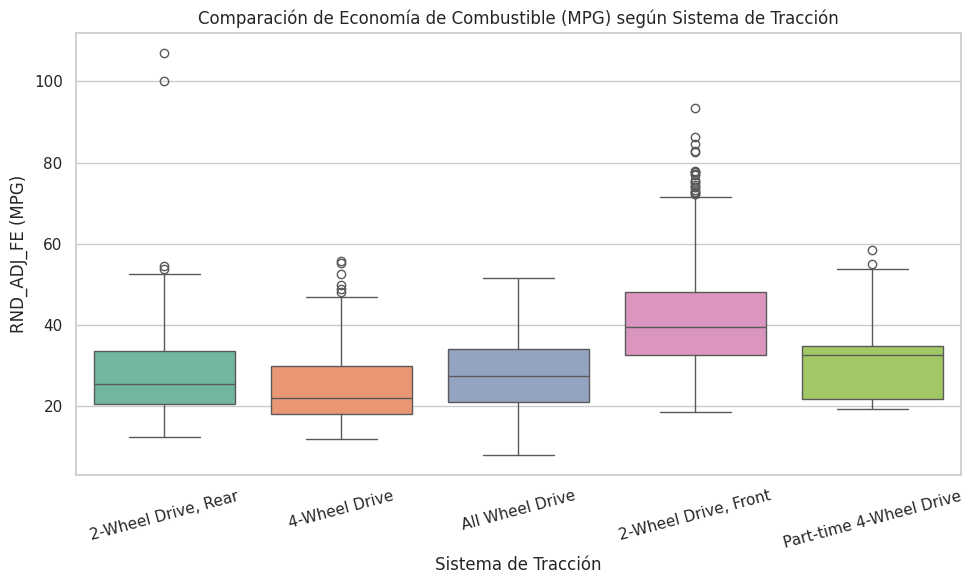

In [107]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df_filtrado, x='Drive System Description', y='RND_ADJ_FE', palette='Set2')
plt.title('Comparación de Economía de Combustible (MPG) según Sistema de Tracción', fontsize=12)
plt.xlabel('Sistema de Tracción')
plt.ylabel('RND_ADJ_FE (MPG)') 
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## 2.3 Validación de Hipótesis Multivariadas

### 2.3.1 Hipótesis multivariada - Resistencia inicial al avance

Se crea un diccionario para aislar los datos y no trabajr sobre todo el dataset y 

In [108]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración visual global para gráficos (estándar Colab)
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 10

# Uilizamos diccionarios que
dataset = dict()

# 2. Metadatos de la Hipótesis 4
dataset['h4_nombre'] = 'H4: Resistencia Inicial al Avance (Target Coef A)'
dataset['h4_var_dep'] = 'Target Coef A (lbf)'
dataset['h4_var_indep_num'] = ['Equivalent Test Weight (lbs.)']
dataset['h4_var_indep_cat'] = ['Vehicle Type', 'Drive System Code']

# Lista consolidada de las 4 variables involucradas
dataset['h4_cols'] = [dataset['h4_var_dep']] + dataset['h4_var_indep_num'] + dataset['h4_var_indep_cat']

# 3. Carga e incorporación del DataFrame original al diccionario
# (Reemplazar 'df_epa' por la variable con la que se cargó el CSV inicial)
dataset['raw'] = clean_df.copy()

print(f"Diccionario 'dataset' inicializado correctamente.")
print(f"Variables seleccionadas para H4: {dataset['h4_cols']}")

Diccionario 'dataset' inicializado correctamente.
Variables seleccionadas para H4: ['Target Coef A (lbf)', 'Equivalent Test Weight (lbs.)', 'Vehicle Type', 'Drive System Code']


In [110]:
#aislamos el conjunto de datos para la hipótesis
dataset['h4_df'] = dataset['raw'][dataset['h4_cols']].copy()
dataset['h4_df'].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4014 entries, 0 to 4013
Data columns (total 4 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Target Coef A (lbf)            4014 non-null   float64
 1   Equivalent Test Weight (lbs.)  4014 non-null   int64  
 2   Vehicle Type                   4014 non-null   object 
 3   Drive System Code              4014 non-null   object 
dtypes: float64(1), int64(1), object(2)
memory usage: 125.6+ KB


In [111]:
print("\n valores únicos en variables categóricas")
for cat_col in dataset['h4_var_indep_cat']:
    print(f"\nCategorías en '{cat_col}':")
    print(dataset['h4_df'][cat_col].value_counts(dropna=False))


 valores únicos en variables categóricas

Categorías en 'Vehicle Type':
Vehicle Type
Truck    1906
Car      1560
Both      548
Name: count, dtype: int64

Categorías en 'Drive System Code':
Drive System Code
F    1376
A    1331
R     884
4     350
P      73
Name: count, dtype: int64


In [112]:
# Definición de diccionarios de mapeo integrados en 'dataset', basados en el dominio técnico de la EPA. Hacemos encoding de los datos categóricos

dataset['map_vehicle'] = {  # el juntar truck y both ayuda para testear si la estructura de vehículo pesado incrementa el Coef A.
    'Truck': 1,
    'Both': 1, # juntamos both y truck por que desde el punto de vista de la resistencia mecánica en el dinamómetro (Target Coef A), estos vehículos comparten varias cosas en cuanto a mecanica con las camionetas
    'Car': 0
}

# Mapeo de Drive System Code: hacemos 1 conjunto de 4-Wheel Drive
dataset['map_drive'] = {
    'A': 1,  # All-Wheel Drive
    '4': 1,  # 4-Wheel Drive
    'P': 1,  # Part-time 4WD
    'F': 0,  # Front-Wheel Drive (2WD)
    'R': 0   # Rear-Wheel Drive (2WD)
}

# 2. Aplicación de los mapeos al DataFrame de la hipótesis
dataset['h4_df']['Es_Truck_o_Both'] = dataset['h4_df']['Vehicle Type'].map(dataset['map_vehicle'])
dataset['h4_df']['Es_AWD_4WD'] = dataset['h4_df']['Drive System Code'].map(dataset['map_drive'])

display(dataset['h4_df'].head())
print(f"====vemos la información de mi diccionario====")

dataset['h4_df'].info()

,Target Coef A (lbf),Equivalent Test Weight (lbs.),Vehicle Type,Drive System Code,Es_Truck_o_Both,Es_AWD_4WD
0,53.24,4500,Car,R,0,0
1,53.24,4500,Car,R,0,0
2,60.68,5500,Both,4,1,1
3,60.68,5500,Both,4,1,1
4,49.17,4500,Car,R,0,0


====vemos la información de mi diccionario====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4014 entries, 0 to 4013
Data columns (total 6 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Target Coef A (lbf)            4014 non-null   float64
 1   Equivalent Test Weight (lbs.)  4014 non-null   int64  
 2   Vehicle Type                   4014 non-null   object 
 3   Drive System Code              4014 non-null   object 
 4   Es_Truck_o_Both                4014 non-null   int64  
 5   Es_AWD_4WD                     4014 non-null   int64  
dtypes: float64(1), int64(3), object(2)
memory usage: 188.3+ KB


In [113]:
# se crea variable combinada (Grupo_interaccion) para facilitar la visualización en los gráficos 
def etiquetar_grupo(row):
    tipo = "Truck/Both" if row['Es_Truck_o_Both'] == 1 else "Car"
    traccion = "AWD/4WD" if row['Es_AWD_4WD'] == 1 else "2WD"
    return f"{tipo} | {traccion}"

dataset['h4_df']['Grupo_Interaccion'] = dataset['h4_df'].apply(etiquetar_grupo, axis=1)

print("Mapeo y recodificación ejecutados exitosamente.")
dataset['h4_df'][['Vehicle Type', 'Es_Truck_o_Both', 'Drive System Code', 'Es_AWD_4WD', 'Grupo_Interaccion']].head()

Mapeo y recodificación ejecutados exitosamente.


,Vehicle Type,Es_Truck_o_Both,Drive System Code,Es_AWD_4WD,Grupo_Interaccion
0,Car,0,R,0,Car | 2WD
1,Car,0,R,0,Car | 2WD
2,Both,1,4,1,Truck/Both | AWD/4WD
3,Both,1,4,1,Truck/Both | AWD/4WD
4,Car,0,R,0,Car | 2WD


In [114]:
dataset['h4_df'].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4014 entries, 0 to 4013
Data columns (total 7 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Target Coef A (lbf)            4014 non-null   float64
 1   Equivalent Test Weight (lbs.)  4014 non-null   int64  
 2   Vehicle Type                   4014 non-null   object 
 3   Drive System Code              4014 non-null   object 
 4   Es_Truck_o_Both                4014 non-null   int64  
 5   Es_AWD_4WD                     4014 non-null   int64  
 6   Grupo_Interaccion              4014 non-null   object 
dtypes: float64(1), int64(3), object(3)
memory usage: 219.6+ KB


In [115]:
# cantidad de vehículos que siguen esa configuración
dataset['h4_df']['Grupo_Interaccion'].value_counts().to_frame('Cantidad_Vehiculos')

,Cantidad_Vehiculos
Grupo_Interaccion,
Truck/Both | 2WD,1266
Truck/Both | AWD/4WD,1188
Car | 2WD,994
Car | AWD/4WD,566


In [116]:
dataset['h4_df'][[dataset['h4_var_dep'], 'Equivalent Test Weight (lbs.)']].describe().T

,count,mean,std,min,25%,50%,75%,max
Target Coef A (lbf),4014.0,40.186493,12.511286,16.14,31.1,38.69,46.5,93.0
Equivalent Test Weight (lbs.),4014.0,4811.503488,989.182010,2750.00,4000.0,4750.00,5500.0,9000.0


#### 2.3.1.1 Gráficos para análisis previo a los tests

##### Análisis univariado

=== ESTADÍSTICA DESCRIPTIVA: VARIABLES CUANTITATIVAS ===


,mean,std,min,50%,max,skewness,kurtosis
Target Coef A (lbf),40.186493,12.511286,16.14,38.69,93.0,0.985945,1.392131
Equivalent Test Weight (lbs.),4811.503488,989.182010,2750.00,4750.00,9000.0,0.611346,0.452185


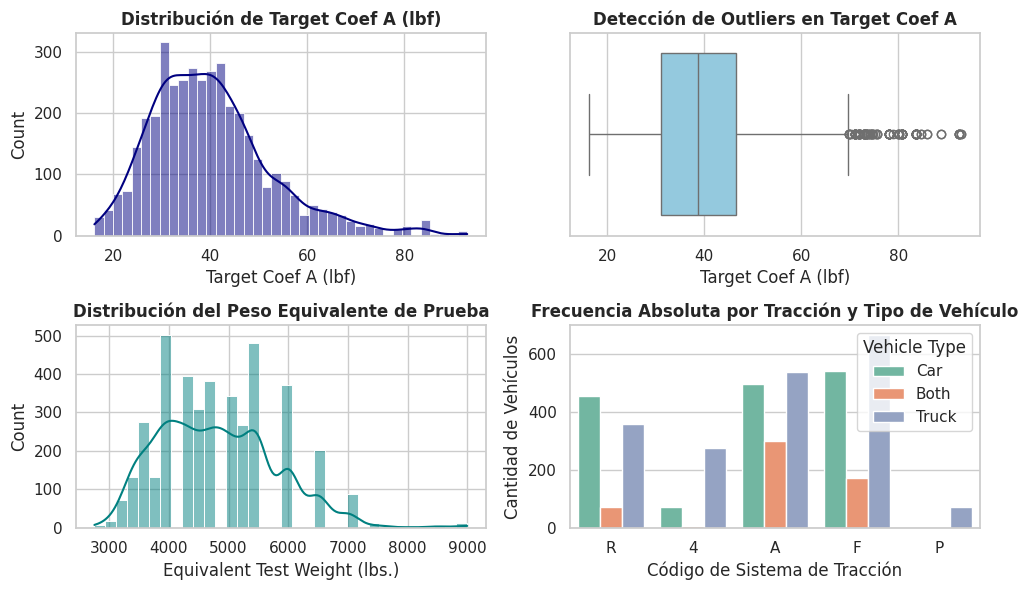

In [117]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Tabla de Estadísticos Descriptivos Cuantitativos
print("=== ESTADÍSTICA DESCRIPTIVA: VARIABLES CUANTITATIVAS ===")
stats_num = dataset['h4_df'][[dataset['h4_var_dep'], 'Equivalent Test Weight (lbs.)']].describe().T
stats_num['skewness'] = dataset['h4_df'][[dataset['h4_var_dep'], 'Equivalent Test Weight (lbs.)']].skew()
stats_num['kurtosis'] = dataset['h4_df'][[dataset['h4_var_dep'], 'Equivalent Test Weight (lbs.)']].kurt()
display(stats_num[['mean', 'std', 'min', '50%', 'max', 'skewness', 'kurtosis']])

# 2. Gráfico 1: Distribución Univariada de Target Coef A y Peso Equivalente. Creamos como n dashboard, una matriz de  2x2 en 1 figura
fig, axes = plt.subplots(2, 2)

# Subplot A: Histograma Target Coef A
sns.histplot(data=dataset['h4_df'], x=dataset['h4_var_dep'], kde=True, ax=axes[0,0], color='navy')
axes[0,0].set_title('Distribución de Target Coef A (lbf)', fontweight='bold')
axes[0,0].set_xlabel('Target Coef A (lbf)')

# Subplot B: Boxplot Target Coef A
sns.boxplot(data=dataset['h4_df'], x=dataset['h4_var_dep'], ax=axes[0,1], color='skyblue')
axes[0,1].set_title('Detección de Outliers en Target Coef A', fontweight='bold')
axes[0,1].set_xlabel('Target Coef A (lbf)')

# Subplot C: Histograma Peso Equivalente --> visualización de l avairbailidad de Equivalent Test Weight (lbs.)
sns.histplot(data=dataset['h4_df'], x='Equivalent Test Weight (lbs.)', kde=True, ax=axes[1,0], color='teal')
axes[1,0].set_title('Distribución del Peso Equivalente de Prueba', fontweight='bold')
axes[1,0].set_xlabel('Equivalent Test Weight (lbs.)')

# Subplot D: Frecuencias de Categorías de Tracción
sns.countplot(data=dataset['h4_df'], x='Drive System Code', hue='Vehicle Type', ax=axes[1,1], palette='Set2')
axes[1,1].set_title('Frecuencia Absoluta por Tracción y Tipo de Vehículo', fontweight='bold')
axes[1,1].set_xlabel('Código de Sistema de Tracción')
axes[1,1].set_ylabel('Cantidad de Vehículos')

plt.tight_layout()  #ajusta automáticamente los márgenes y espacios entre los 4 subplots
plt.show()

# el prefijo set, ejemplo axes[].set_title es la sintaxis orientada a objetos de Axes.
# ax=  axes[,] elije el cuadrante de la caja de 2x2 donde se va a posicionar el gráfico

##### 2.3.2.2 Análisis bivariado sobre hipótesis multivariada

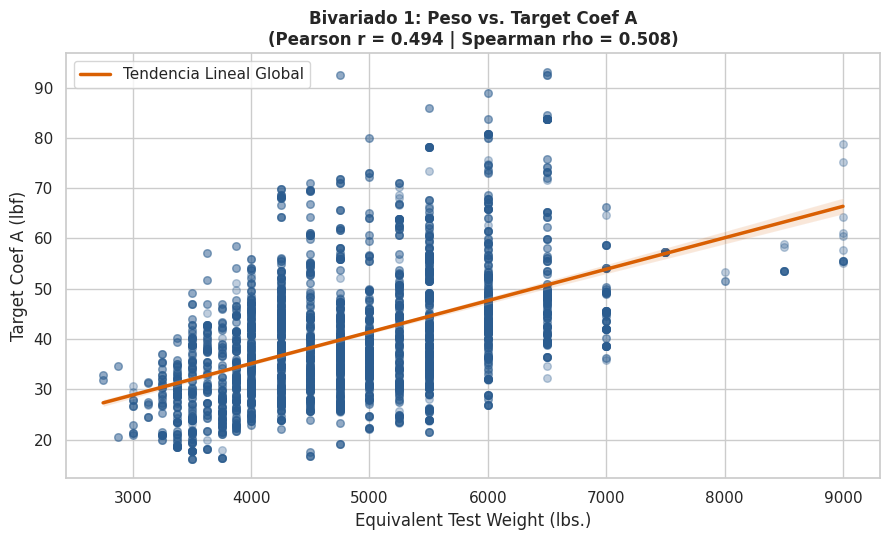

In [118]:
import seaborn as sns
#Gráfico Bivariado 1: Scatter plot simple y Recta de regresión global
plt.figure(figsize=(9, 5.5))

sns.regplot(
    data=dataset['h4_df'],
    x='Equivalent Test Weight (lbs.)',
    y=dataset['h4_var_dep'],
    scatter_kws={'alpha': 0.3, 'color': '#2b5c8f', 's': 30},
    line_kws={'color': '#d95f02', 'linewidth': 2.5, 'label': 'Tendencia Lineal Global'}
)

# Cálculo de correlaciones (Pearson y Spearman)
corr_p = dataset['h4_df']['Equivalent Test Weight (lbs.)'].corr(dataset['h4_df'][dataset['h4_var_dep']], method='pearson')
corr_s = dataset['h4_df']['Equivalent Test Weight (lbs.)'].corr(dataset['h4_df'][dataset['h4_var_dep']], method='spearman')

plt.title(f'Bivariado 1: Peso vs. Target Coef A\n(Pearson r = {corr_p:.3f} | Spearman rho = {corr_s:.3f})', fontweight='bold')
plt.xlabel('Equivalent Test Weight (lbs.)')
plt.ylabel('Target Coef A (lbf)')
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()
# 

#####  Análisis multivariado

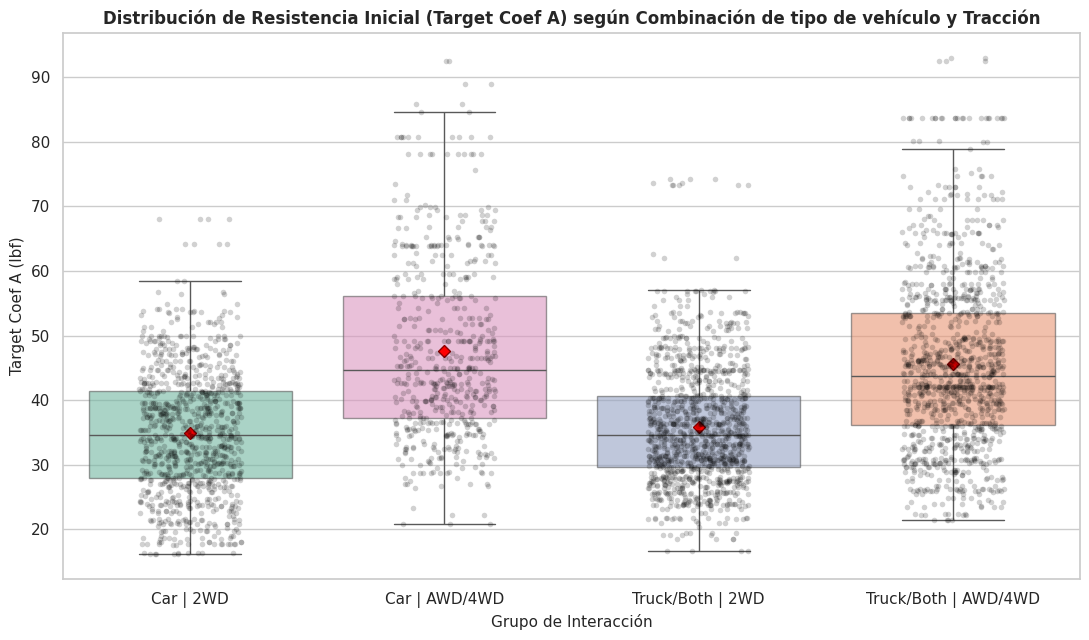

=== ESTADÍSTICOS DESCRIPTIVOS DETALLADOS POR GRUPO ===


,N,Media (x̄),Desv_Std (s),min,Mediana,max,IQR
Grupo_Interaccion,,,,,,,
Car | 2WD,994.0,34.985745,9.557275,16.140,34.590,68.000,13.4260
Car | AWD/4WD,566.0,47.588657,13.875026,20.870,44.660,92.555,19.0000
Truck/Both | 2WD,1266.0,35.899396,8.957894,16.651,34.550,74.240,11.0375
Truck/Both | AWD/4WD,1188.0,45.579912,13.347097,21.530,43.819,93.000,17.3100


In [119]:
# Gráfico multivariado 2: Cruzamos Tipo de vehiculo y tracción frente a Target COef A

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Ordenamos lo grupos seg'un sentencia lógica
orden_grupos = [
    'Car | 2WD',
    'Car | AWD/4WD',
    'Truck/Both | 2WD',
    'Truck/Both | AWD/4WD',
]

plt.figure(figsize=(11, 6.5))

# Creamos el boxplot con indicador visual de la MEDIA (Diamante Rojo)
ax = sns.boxplot(
    data=dataset['h4_df'],
    x='Grupo_Interaccion',
    y=dataset['h4_var_dep'],
    hue='Grupo_Interaccion', 
    legend=False,
    order=orden_grupos,
    palette='Set2',
    boxprops=dict(alpha=0.6),
    fliersize=0,  # Evita duplicar outliers con el stripplot
    showmeans=True,  # Grafica la media
    meanprops=dict(
        marker='D', markeredgecolor='darkred', markerfacecolor='red', markersize=6
    ),
)

# stripplot (Puntos individuales con transparencia)(on puntos reales observados)
sns.stripplot(
    data=dataset['h4_df'],
    x='Grupo_Interaccion',
    y=dataset['h4_var_dep'],
    order=orden_grupos,
    color='black',
    alpha=0.18,
    jitter=0.2,
    size=4,
)

# Formato de títulos y ejes

plt.title('Distribución de Resistencia Inicial (Target Coef A) según Combinación de tipo de vehículo y Tracción', fontweight='bold', fontsize=12)
plt.xlabel('Grupo de Interacción', fontsize=11)
plt.ylabel('Target Coef A (lbf)', fontsize=11)
plt.tight_layout()
plt.show()

# 5. Tabla descriptiva complementaria en formato de Pandas
print('=== ESTADÍSTICOS DESCRIPTIVOS DETALLADOS POR GRUPO ===')
tabla_resumen = (
    dataset['h4_df']
    .groupby('Grupo_Interaccion')[dataset['h4_var_dep']]
    .describe()
)
tabla_resumen['IQR'] = tabla_resumen['75%'] - tabla_resumen['25%']
display(
    tabla_resumen[['count', 'mean', 'std', 'min', '50%', 'max', 'IQR']].rename(
        columns={
            'count': 'N',
            'mean': 'Media (x̄)',
            'std': 'Desv_Std (s)',
            '50%': 'Mediana',
        }
    )
)

#### 2.3.1.2 Validación de las hipótesis

diagnóstico de multicolinealidad (VIF)


,Predictor,VIF
0,Equivalent Test Weight (lbs.),1.533250
1,Es_Truck_o_Both,1.123297
2,Es_AWD_4WD,1.390534


Resumen de modelo de regresion lineal simple (VALIDACIÓN H4)
                               OLS Regression Results                               
Dep. Variable:     Q("Target Coef A (lbf)")   R-squared:                       0.297
Model:                                  OLS   Adj. R-squared:                  0.296
Method:                       Least Squares   F-statistic:                     423.0
Date:                      Tue, 10 Nov 2026   Prob (F-statistic):          1.88e-304
Time:                              23:46:33   Log-Likelihood:                -15130.
No. Observations:                      4014   AIC:                         3.027e+04
Df Residuals:                          4009   BIC:                         3.030e+04
Df Model:                                 4                                         
Covariance Type:                  nonrobust                                         
                                         coef    std err          t      P>|t|      [0.02

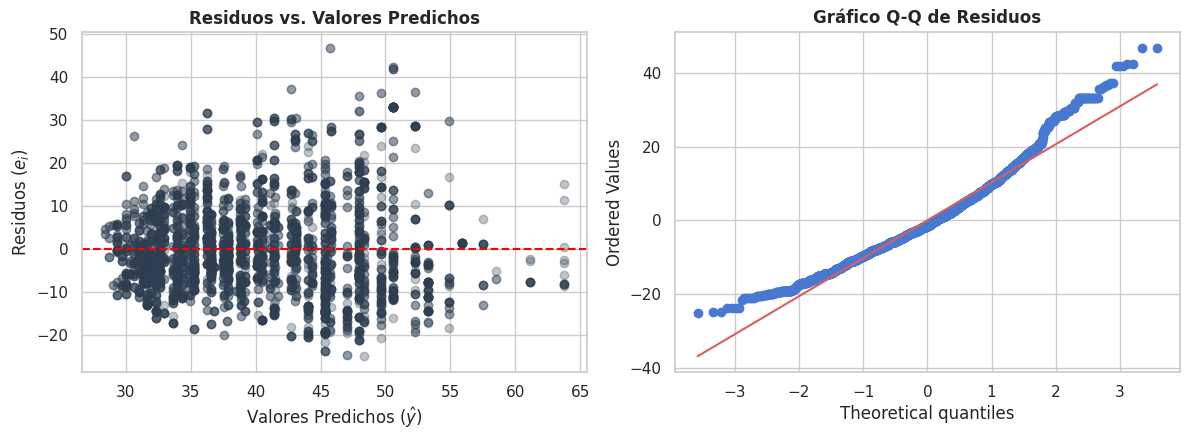

In [120]:
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
import scipy.stats as stats
import matplotlib.pyplot as plt


# 1. DIAGNÓSTICO DE MULTICOLINEALIDAD (VIF)
# Usamos las variables cuantitativas y binarias ya creadas en dataset['h4_df']

X_vif = dataset["h4_df"][["Equivalent Test Weight (lbs.)", "Es_Truck_o_Both", "Es_AWD_4WD"]].dropna()
X_vif_const = sm.add_constant(X_vif)

vif_df = pd.DataFrame({
    "Predictor": X_vif_const.columns[1:],
    "VIF": [variance_inflation_factor(X_vif_const.values, i) for i in range(1, X_vif_const.shape[1])]
})

print("diagnóstico de multicolinealidad (VIF)")
display(vif_df)



# 2. AJUSTE DEL MODELO DE REGRESIÓN LINEAL MÚLTIPLE (OLS)
# Se incluye el término de interacción entre la estructura y la tracción

formula_h4 = 'Q("Target Coef A (lbf)") ~ Q("Equivalent Test Weight (lbs.)") + Es_Truck_o_Both * Es_AWD_4WD'
modelo_h4 = smf.ols(formula=formula_h4, data=dataset["h4_df"]).fit()

print("Resumen de modelo de regresion lineal simple (VALIDACIÓN H4)")
print(modelo_h4.summary())

#para ver si rechazo H0 miro Prob (F-statistic):          1.64e-286, la cual es menor a 0.05 entonces se rechaza H0



# 3. diangnóstico gráfico de residuos (SUPUESTOS DE HOMOCEDASTICIDAD Y NORMALIDAD)
# residuo es la diferencia entre le vlaor real meiddo en el laboratorio (y) y el vlor que predice mi modelo
# es necesario caluclarlo pq la regresión OLS exige que los errores sean ruido aleatorio sin patrones

residuos = modelo_h4.resid
valores_ajustados = modelo_h4.fittedvalues

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# A. Residuos vs Valores Predichos (Evalúa Homocedasticidad)
axes[0].scatter(valores_ajustados, residuos, alpha=0.3, color='#2c3e50')
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_title('Residuos vs. Valores Predichos', fontweight='bold')
axes[0].set_xlabel(r'Valores Predichos ($\hat{y}$)')
axes[0].set_ylabel('Residuos ($e_i$)')

# B. Q-Q Plot de Residuos (Evalúa Normalidad)
stats.probplot(residuos, dist="norm", plot=axes[1])
axes[1].set_title('Gráfico Q-Q de Residuos', fontweight='bold')

plt.tight_layout()
plt.show()

##### 2.3.2 Análisis multivariado provisto por la cátedra

Observaciones válidas para H6 (sin eléctricos ni NaNs): 1427

 diagnóstico de multicolinealidad (VIF (Variance Inflation Factor))


,Predictor,VIF
0,Peso,1.706603
1,Potencia,3.574709
2,Cilindrada,6.858723
3,Cilindros,9.724267
4,Es_Automatica,1.360607
5,Es_AWD_4WD,1.372725



Resumen del modelo OLS (validación H6)
                            OLS Regression Results                            
Dep. Variable:             RND_ADJ_FE   R-squared:                       0.601
Model:                            OLS   Adj. R-squared:                  0.599
Method:                 Least Squares   F-statistic:                     355.9
Date:                Tue, 10 Nov 2026   Prob (F-statistic):          9.36e-279
Time:                        23:46:37   Log-Likelihood:                -4783.7
No. Observations:                1427   AIC:                             9581.
Df Residuals:                    1420   BIC:                             9618.
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Interc

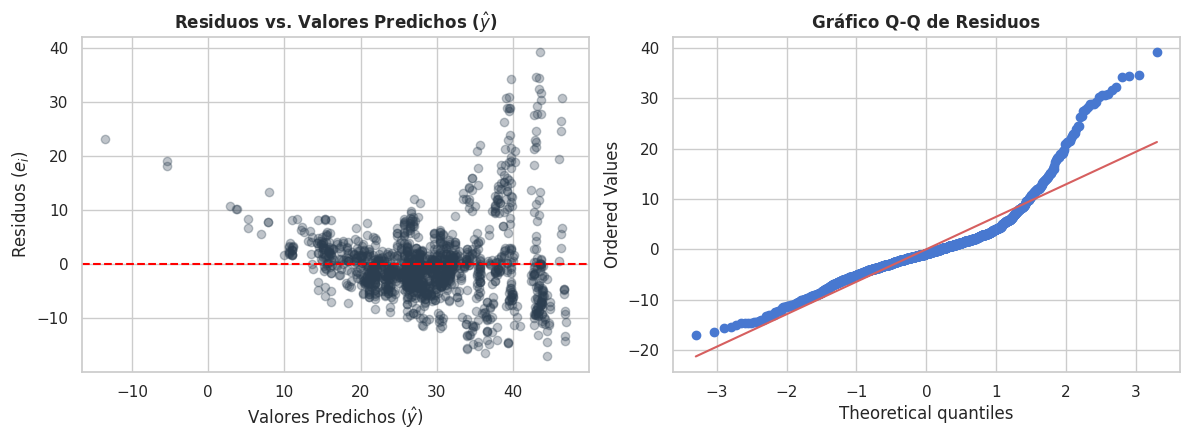

In [121]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
import scipy.stats as stats
import matplotlib.pyplot as plt

# 1. aislamos el subconjunto en el diccionario
dataset['h6_nombre'] = 'H6: Características Técnicas y Eficiencia Urbana (FTP)'
dataset['h6_var_dep'] = 'RND_ADJ_FE'

# Filtrado de dominio:
# 1. Vehículos a combustión (excluye 'Electricity')
# 2. Protocolo urbano FTP
# 3. Registros con RND_ADJ_FE válido (descartamos los NaN creados por los centinelas >= 9990)
cond_combustion = (clean_df["Test Fuel Type Description"] != "Electricity")
cond_urbano = (clean_df["Test Category"] == "FTP")
cond_fe_valido = clean_df["RND_ADJ_FE"].notna()

dataset["h6_df"] = clean_df[cond_combustion & cond_urbano & cond_fe_valido].copy()

# Binarización / Normalización de categóricas para el modelo
dataset["h6_df"]["Es_AWD_4WD"] = dataset["h6_df"]["Drive System Code"].map({'A': 1, '4': 1, 'P': 1, 'F': 0, 'R': 0})
dataset["h6_df"]["Es_Automatica"] = np.where(dataset["h6_df"]["Tested Transmission Type"].astype(str).str.contains('Auto', case=False, na=False), 1, 0)

# Renombrar columnas con caracteres especiales para facilitar la fórmula de statsmodels
dataset["h6_df"]["Cilindros"] = dataset["h6_df"]["# of Cylinders and Rotors"]
dataset["h6_df"]["Peso"] = dataset["h6_df"]["Equivalent Test Weight (lbs.)"]
dataset["h6_df"]["Potencia"] = dataset["h6_df"]["Rated Horsepower"]
dataset["h6_df"]["Cilindrada"] = dataset["h6_df"]["Test Veh Displacement (L)"]

# Filtrar observaciones completas sin nulos en las variables del modelo
cols_h6_modelo = [dataset["h6_var_dep"], "Peso", "Potencia", "Cilindrada", "Cilindros", "Es_Automatica", "Es_AWD_4WD"]
dataset["h6_df"] = dataset["h6_df"][cols_h6_modelo].dropna().reset_index(drop=True)

print(f"Observaciones válidas para H6 (sin eléctricos ni NaNs): {len(dataset["h6_df"])}")



# 2. DIAGNÓSTICO DE MULTICOLINEALIDAD (VIF) (prueba que se realzia antes de interpretar un modelo de regresión líneal múltiple para comprobar si las variables independientes estan fuertemente correlacionadas entre sí)

X_vif = dataset["h6_df"][["Peso", "Potencia", "Cilindrada", "Cilindros", "Es_Automatica", "Es_AWD_4WD"]]
X_vif_const = sm.add_constant(X_vif)

vif_df = pd.DataFrame({
    "Predictor": X_vif_const.columns[1:],
    "VIF": [variance_inflation_factor(X_vif_const.values, i) for i in range(1, X_vif_const.shape[1])]
})

print("\n diagnóstico de multicolinealidad (VIF (Variance Inflation Factor))")
display(vif_df)



# 3. AJUSTE DEL MODELO DE REGRESIÓN LINEAL MÚLTIPLE (OLS)

formula_h6 = f'{dataset["h6_var_dep"]} ~ Peso + Potencia + Cilindrada + Cilindros + Es_Automatica + Es_AWD_4WD'
modelo_h6 = smf.ols(formula=formula_h6, data=dataset["h6_df"]).fit()

print("\nResumen del modelo OLS (validación H6)")
print(modelo_h6.summary())



# 4. diagnóstico gráfico de residuos

residuos_h6 = modelo_h6.resid
valores_predichos_h6 = modelo_h6.fittedvalues

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Residuos vs Predichos (Homocedasticidad)
axes[0].scatter(valores_predichos_h6, residuos_h6, alpha=0.3, color="#2c3e50")
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_title(r"Residuos vs. Valores Predichos ($\hat{y}$)", fontweight="bold")
axes[0].set_xlabel(r"Valores Predichos ($\hat{y}$)")
axes[0].set_ylabel(r"Residuos ($e_i$)")

# Q-Q Plot (Normalidad de errores)
stats.probplot(residuos_h6, dist="norm", plot=axes[1])
axes[1].set_title("Gráfico Q-Q de Residuos", fontweight="bold")

plt.tight_layout()
plt.show()